In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

cwd = Path.cwd().resolve()

PROJECT_ROOT = next(
    (p for p in [cwd, *cwd.parents]
     if (p / "research_xai" / "results").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found")

RESULTS = PROJECT_ROOT / "research_xai" / "results"

XAI_ROOT = (
    RESULTS / "reduced_grid_225_v1"
    / "xai" / "p100_h8"
)

BASELINE_ROOT = RESULTS / "baseline_controls_p100_h8"

FIGURES_DIR = (
    PROJECT_ROOT / "research_xai"
    / "notebooks" / "visualization"
    / "figures" / "02_forecasting"
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

DATASET_MAP = {
    "Electricity": "energy",
    "Financial": "financial",
    "CMIP6 Wind": "wind",
    "CMIP6 Pressure": "pressure",
    "Lorenz": "lorenz"
}

DATASETS = list(DATASET_MAP)

MODEL_ORDER = [
    "M0", "M1", "M2", "M3", "M4",
    "LSTM", "DLinear"
]

MODEL_COLORS = {
    "M0": "#64748B",
    "M1": "#2563EB",
    "M2": "#06B6D4",
    "M3": "#8B5CF6",
    "M4": "#F59E0B",
    "LSTM": "#10B981",
    "DLinear": "#EF4444"
}

LOOKBACK = 100
HORIZON = 8
SEED = 7

sns.set_theme(style="whitegrid", context="paper")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

availability = []

for dataset, key in DATASET_MAP.items():
    shared_path = XAI_ROOT / key / "shared_test_cases.npz"

    if not shared_path.is_file():
        raise FileNotFoundError(shared_path)

    with np.load(shared_path, allow_pickle=False) as shared:
        x = shared["x"]
        y = shared["y"]
        indices = shared["sample_indices"]

    assert x.ndim == 3
    assert x.shape[0] == y.shape[0] == len(indices)
    assert x.shape[1] == LOOKBACK
    assert y.shape == (len(indices), x.shape[2] * HORIZON)
    assert np.isfinite(x).all() and np.isfinite(y).all()

    for model in MODEL_ORDER:
        if model in ["LSTM", "DLinear"]:
            path = (
                BASELINE_ROOT / key / model
                / "p100_h8_e4000_b32_s7"
                / "checkpoint_best.pt"
            )
            source = "Checkpoint"
        else:
            path = (
                XAI_ROOT / key / model
                / "xai_arrays.npz"
            )
            source = "Saved predictions"

        availability.append({
            "dataset": dataset,
            "model": model,
            "source": source,
            "available": path.is_file(),
            "samples": len(indices),
            "channels": x.shape[2]
        })

availability_df = pd.DataFrame(availability)

print("Project:", PROJECT_ROOT)
print("Forecast figures:", FIGURES_DIR)
print("Available sources:",
      int(availability_df["available"].sum()),
      "/", len(availability_df))

display(
    availability_df.pivot(
        index="dataset",
        columns="model",
        values="available"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    )
)

print("\nTest window information:")
display(
    availability_df.groupby("dataset", as_index=False)
    [["samples", "channels"]].first()
)

if not availability_df["available"].all():
    print("\nMissing sources:")
    display(availability_df[~availability_df["available"]])
else:
    print("\n[PASS] All forecasting sources available")

Project: C:\Users\Win 11 New\Desktop\pa gk
Forecast figures: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\figures\02_forecasting
Available sources: 35 / 35


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,True,True,True,True,True,True,True
Financial,True,True,True,True,True,True,True
CMIP6 Wind,True,True,True,True,True,True,True
CMIP6 Pressure,True,True,True,True,True,True,True
Lorenz,True,True,True,True,True,True,True



Test window information:


,dataset,samples,channels
0,CMIP6 Pressure,8,5
1,CMIP6 Wind,8,5
2,Electricity,8,6
3,Financial,8,2
4,Lorenz,8,3



[PASS] All forecasting sources available


In [ ]:
import sys
from pathlib import Path
import importlib.util

project_path = str(PROJECT_ROOT.resolve())

if project_path not in sys.path:
    sys.path.insert(0, project_path)

assert (PROJECT_ROOT / "research_xai" / "data" / "dataset.py").is_file(), (
    "Cannot locate research_xai/data/dataset.py"
)

importlib.invalidate_caches()

print("Project root:", PROJECT_ROOT)
print("Python:", sys.executable)
print("research_xai:", importlib.util.find_spec("research_xai"))

import hashlib

from research_xai.data.dataset import prepare_dataset
from research_xai.training.trainer import calculate_data_hash
from research_xai.models.baselines import (
    LSTMForecaster,
    DLinearForecaster
)

forecast_data = {}
verification_records = []

for dataset_name, dataset_key in DATASET_MAP.items():
    data = prepare_dataset(
        dataset_name,
        seq_len=LOOKBACK,
        horizon=HORIZON
    )

    data_hash = calculate_data_hash(
        data["x_train"],
        data["y_train"],
        data["x_val"],
        data["y_val"]
    )

    shared_path = (
        XAI_ROOT / dataset_key / "shared_test_cases.npz"
    )

    with np.load(shared_path, allow_pickle=False) as shared:
        x = shared["x"].copy()
        y = shared["y"].copy()
        indices = shared["sample_indices"].copy()

    n_samples, seq_len, channels = x.shape

    assert n_samples == 8
    assert seq_len == LOOKBACK
    assert y.shape == (n_samples, channels * HORIZON)
    assert len(np.unique(indices)) == n_samples

    np.testing.assert_allclose(
        x,
        data["x_test"][indices].numpy(),
        rtol=0,
        atol=1e-6
    )

    np.testing.assert_allclose(
        y,
        data["y_test"][indices].numpy(),
        rtol=0,
        atol=1e-6
    )

    input_hash = hashlib.sha256(x.tobytes()).hexdigest()

    predictions = {}
    targets = y.reshape(n_samples, channels, HORIZON)

    for model_name in MODEL_ORDER:
        if model_name in ["M0", "M1", "M2", "M3", "M4"]:
            model_dir = XAI_ROOT / dataset_key / model_name

            metadata = json.loads(
                (model_dir / "xai_metadata.json").read_text(
                    encoding="utf-8"
                )
            )

            assert metadata["trained_model"] == model_name
            assert metadata["source_data_hash"] == data_hash
            assert metadata["selected_test_inputs_sha256"] == input_hash
            assert metadata["sample_indices"] == indices.tolist()

            with np.load(
                model_dir / "xai_arrays.npz",
                allow_pickle=False
            ) as saved:
                pred = saved["prediction"].copy()

                selected_pred = saved[
                    "selected_prediction"
                ].copy()

                selected_true = saved[
                    "selected_true"
                ].copy()

            assert metadata["target_channel"] == 0
            assert metadata["target_step_zero_based"] == 7

            np.testing.assert_allclose(
                selected_pred,
                pred[:, 0, 7],
                rtol=1e-5,
                atol=1e-6
            )

            np.testing.assert_allclose(
                selected_true,
                targets[:, 0, 7],
                rtol=1e-5,
                atol=1e-6
            )

            source = "Saved XAI predictions"

        else:
            model_dir = (
                BASELINE_ROOT
                / dataset_key
                / model_name
                / "p100_h8_e4000_b32_s7"
            )

            metrics = json.loads(
                (model_dir / "metrics.json").read_text(
                    encoding="utf-8"
                )
            )

            assert metrics["status"] == "completed"
            assert metrics["model"] == model_name
            assert metrics["data_hash"] == data_hash
            assert metrics["patch"] == LOOKBACK
            assert metrics["horizon"] == HORIZON
            assert metrics["seed"] == SEED

            checkpoint = torch.load(
                model_dir / "checkpoint_best.pt",
                map_location="cpu",
                weights_only=False
            )

            assert checkpoint["variant"] == model_name
            assert checkpoint["data_hash"] == data_hash
            assert checkpoint["epoch"] == metrics["best_epoch"]
            assert checkpoint["config"] == metrics["config"]

            if model_name == "LSTM":
                model = LSTMForecaster(
                    input_dim=channels,
                    seq_len=LOOKBACK,
                    horizon=HORIZON,
                    hidden_size=96,
                    num_layers=1
                )
            else:
                model = DLinearForecaster(
                    input_dim=channels,
                    seq_len=LOOKBACK,
                    horizon=HORIZON,
                    moving_avg=25
                )

            model.load_state_dict(
                checkpoint["model"],
                strict=True
            )

            model.eval()

            with torch.no_grad():
                output = model(
                    torch.from_numpy(x).float()
                )

            pred = (
                output.detach()
                .cpu()
                .numpy()
                .reshape(n_samples, channels, HORIZON)
            )

            source = "Best checkpoint inference"

            del model, checkpoint

        assert pred.shape == targets.shape
        assert np.isfinite(pred).all()

        predictions[model_name] = pred

        selected_mse = float(
            np.mean((pred - targets) ** 2)
        )

        verification_records.append({
            "dataset": dataset_name,
            "model": model_name,
            "source": source,
            "samples": n_samples,
            "channels": channels,
            "selected_windows_mse": selected_mse,
            "data_hash_verified": True
        })

    forecast_data[dataset_name] = {
        "x": x,
        "y": targets,
        "sample_indices": indices,
        "predictions": predictions,
        "data_hash": data_hash
    }

    print(
        f"[PASS] {dataset_name}: "
        f"{n_samples} windows | "
        f"{channels} channels | "
        f"{len(predictions)} models"
    )

verification_df = pd.DataFrame(verification_records)

assert len(verification_df) == 35
assert verification_df["data_hash_verified"].all()

selected_mse_table = (
    verification_df.pivot(
        index="dataset",
        columns="model",
        values="selected_windows_mse"
    )
    .reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    )
)

print("\nLoaded predictions:", len(verification_df), "/35")

print("\nMSE ON 8 SELECTED TEST WINDOWS:")
display(
    selected_mse_table.style.format("{:.8f}")
)

verification_df.to_csv(
    FIGURES_DIR / "forecast_source_verification.csv",
    index=False
)

print("\n[PASS] Forecast predictions loaded and verified")


Project root: C:\Users\Win 11 New\Desktop\pa gk
Python: c:\Users\Win 11 New\Desktop\pa gk\.venv\Scripts\python.exe
research_xai: ModuleSpec(name='research_xai', loader=<_frozen_importlib_external.SourceFileLoader object at 0x0000024C24FFB970>, origin='C:\\Users\\Win 11 New\\Desktop\\pa gk\\research_xai\\__init__.py', submodule_search_locations=['C:\\Users\\Win 11 New\\Desktop\\pa gk\\research_xai'])


c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


[PASS] Electricity: 8 windows | 6 channels | 7 models
[PASS] Financial: 8 windows | 2 channels | 7 models
[PASS] CMIP6 Wind: 8 windows | 5 channels | 7 models
[PASS] CMIP6 Pressure: 8 windows | 5 channels | 7 models
[PASS] Lorenz: 8 windows | 3 channels | 7 models

Loaded predictions: 35 /35

MSE ON 8 SELECTED TEST WINDOWS:


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0.01519279,0.02075262,0.01585798,0.01682807,0.01810855,0.01770383,0.01112229
Financial,0.00291118,0.00277613,0.00261294,0.00390764,0.00960724,0.00065902,0.00061088
CMIP6 Wind,0.03526458,0.04158415,0.03582927,0.03314422,0.03440069,0.02781462,0.02187704
CMIP6 Pressure,0.00675349,0.01034766,0.00788214,0.00339011,0.00488414,0.00237062,0.00227076
Lorenz,0.00006189,0.00009677,0.00008886,0.00084805,0.00081892,0.00005772,0.00094618



[PASS] Forecast predictions loaded and verified


In [4]:
XAI_SUMMARY_PATH = XAI_ROOT / "xai_summary.csv"

xai_summary = pd.read_csv(
    XAI_SUMMARY_PATH,
    encoding="utf-8-sig"
)

assert not xai_summary.duplicated(
    ["dataset", "model"]
).any()

xai_lookup = xai_summary.set_index(
    ["dataset", "model"]
)

validation_rows = []
selected_cases = []

for dataset in DATASETS:
    bundle = forecast_data[dataset]

    x = bundle["x"]
    y = bundle["y"]
    indices = bundle["sample_indices"]
    predictions = bundle["predictions"]

    n_samples, channels, horizon = y.shape

    assert n_samples == 8
    assert horizon == HORIZON
    assert len(predictions) == 7

    positions = sorted(set([
        0,
        n_samples // 2,
        n_samples - 1
    ]))

    for position in positions:
        selected_cases.append({
            "dataset": dataset,
            "sample_position": position,
            "test_window_index": int(indices[position]),
            "channels": channels,
            "horizon": horizon
        })

    for model in MODEL_ORDER:
        pred = predictions[model]

        assert pred.shape == y.shape
        assert np.isfinite(pred).all()

        full_output_mse = float(
            np.mean(
                (pred.astype(np.float64) - y) ** 2
            )
        )

        target_mse = float(
            np.mean(
                (
                    pred[:, 0, HORIZON - 1].astype(np.float64)
                    - y[:, 0, HORIZON - 1]
                ) ** 2
            )
        )

        xai_match = None

        if model in ["M0", "M1", "M2", "M3", "M4"]:
            recorded = float(
                xai_lookup.loc[
                    (dataset, model),
                    "selected_windows_mse"
                ]
            )

            np.testing.assert_allclose(
                target_mse,
                recorded,
                rtol=1e-5,
                atol=1e-7,
                err_msg=f"{dataset}/{model}: XAI MSE mismatch"
            )

            xai_match = True

        validation_rows.append({
            "dataset": dataset,
            "model": model,
            "n_windows": n_samples,
            "full_output_mse_8_windows": full_output_mse,
            "xai_target_mse_8_windows": target_mse,
            "xai_summary_verified": xai_match
        })

validation_df = pd.DataFrame(validation_rows)
selected_cases_df = pd.DataFrame(selected_cases)

assert len(validation_df) == 35
assert len(selected_cases_df) == 15

verified = validation_df[
    validation_df["model"].isin(
        ["M0", "M1", "M2", "M3", "M4"]
    )
]

assert verified["xai_summary_verified"].eq(True).all()

print("Forecast sources validated:", len(validation_df), "/35")
print("XAI summary comparisons:", len(verified), "/25")
print("Selected visualization cases:", len(selected_cases_df))

print("\nXAI TARGET MSE — CHANNEL 0, LEAD 8")
display(
    validation_df.pivot(
        index="dataset",
        columns="model",
        values="xai_target_mse_8_windows"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).style.format("{:.8f}")
)

print("\nFIXED TEST WINDOWS FOR VISUALIZATION")
display(selected_cases_df)

validation_df.to_csv(
    FIGURES_DIR / "forecast_consistency_validation.csv",
    index=False
)

selected_cases_df.to_csv(
    FIGURES_DIR / "selected_forecast_cases.csv",
    index=False
)

print("\n[PASS] Forecast consistency validation completed")


Forecast sources validated: 35 /35
XAI summary comparisons: 25 /25
Selected visualization cases: 15

XAI TARGET MSE — CHANNEL 0, LEAD 8


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0.01174881,0.01661300,0.01101010,0.01252580,0.00897002,0.01233848,0.00414448
Financial,0.00343570,0.00192446,0.00178626,0.00805330,0.00610469,0.00100612,0.00184381
CMIP6 Wind,0.01993940,0.02819769,0.00789854,0.00431370,0.00937252,0.00807764,0.02280540
CMIP6 Pressure,0.02921561,0.02965158,0.02129599,0.00904425,0.01253962,0.01459533,0.00911955
Lorenz,0.00003402,0.00010761,0.00007034,0.00087186,0.00279290,0.00007505,0.00422556



FIXED TEST WINDOWS FOR VISUALIZATION


,dataset,sample_position,test_window_index,channels,horizon
0,Electricity,0,0,6,8
1,Electricity,4,337,6,8
2,Electricity,7,591,6,8
3,Financial,0,0,2,8
4,Financial,4,269,2,8
5,Financial,7,471,2,8
6,CMIP6 Wind,0,0,5,8
7,CMIP6 Wind,4,271,5,8
8,CMIP6 Wind,7,475,5,8
9,CMIP6 Pressure,0,0,5,8



[PASS] Forecast consistency validation completed


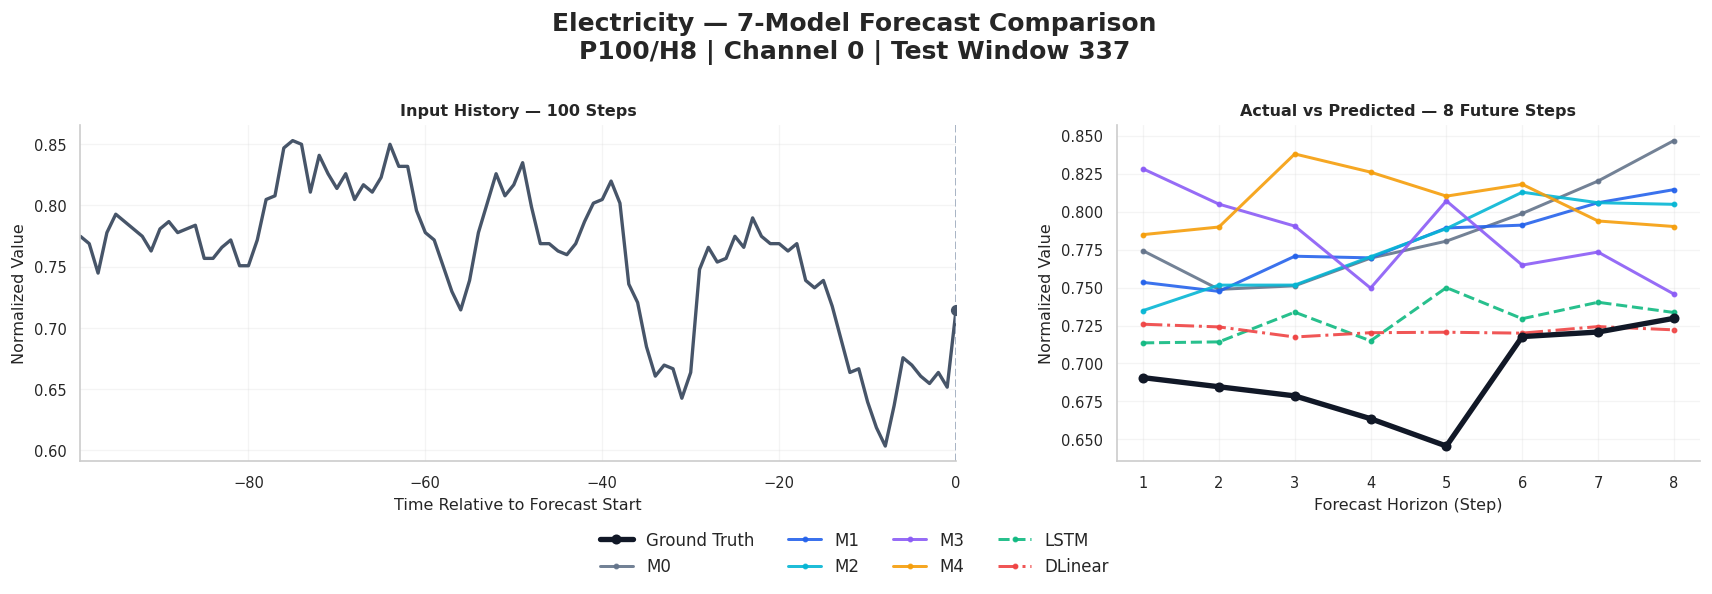

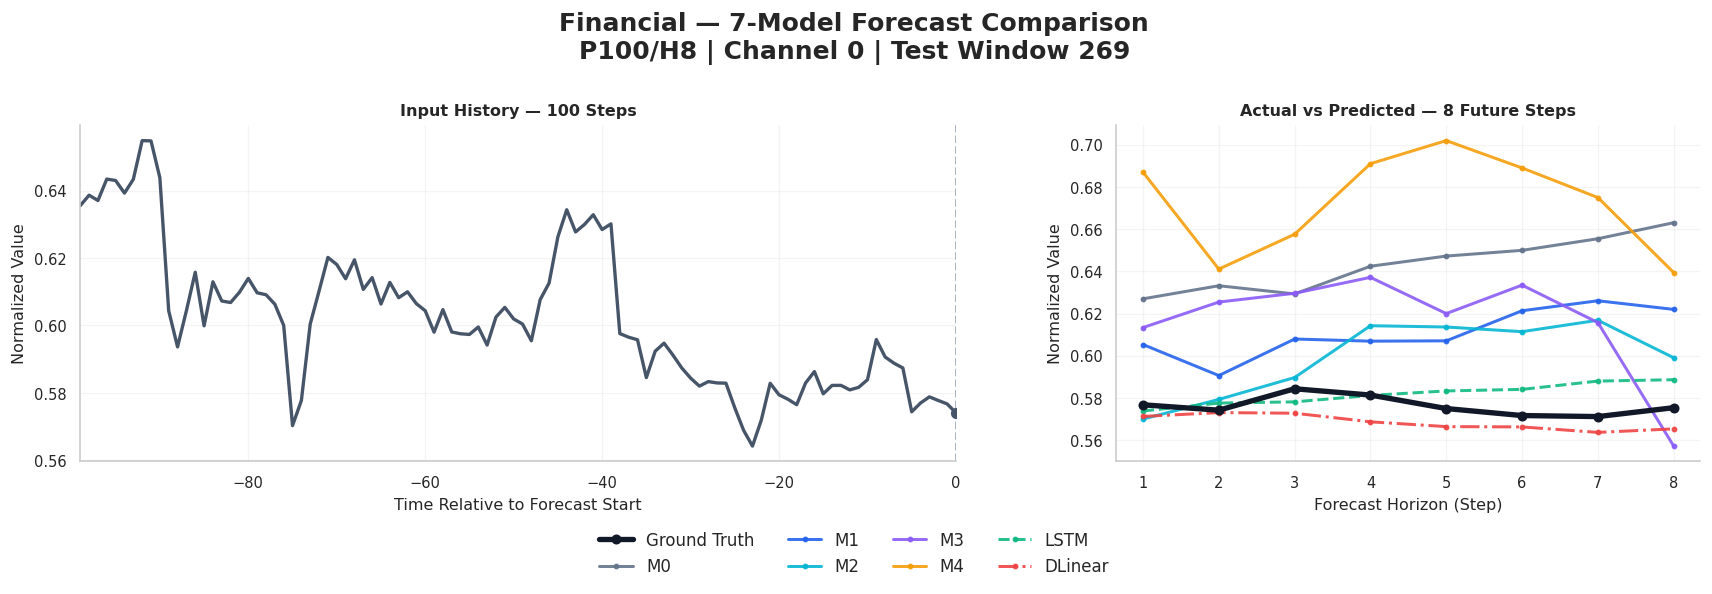

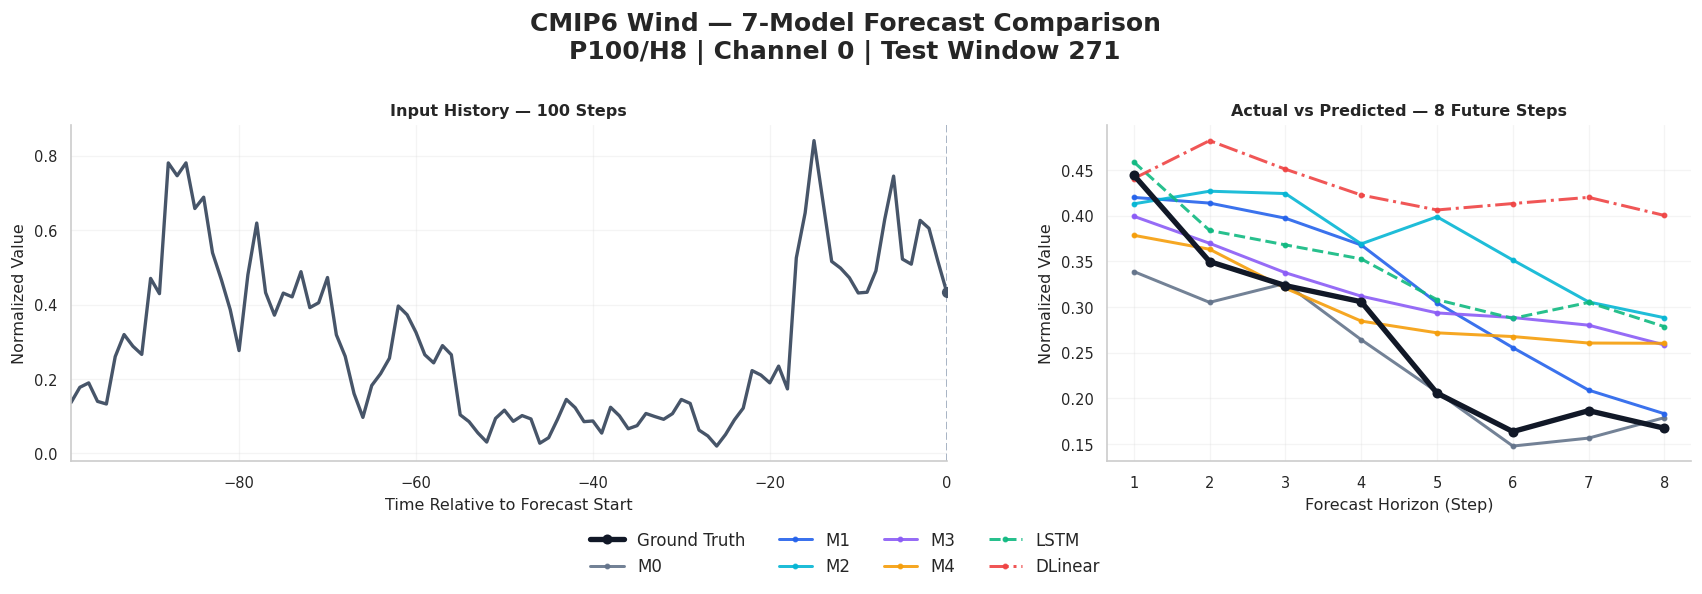

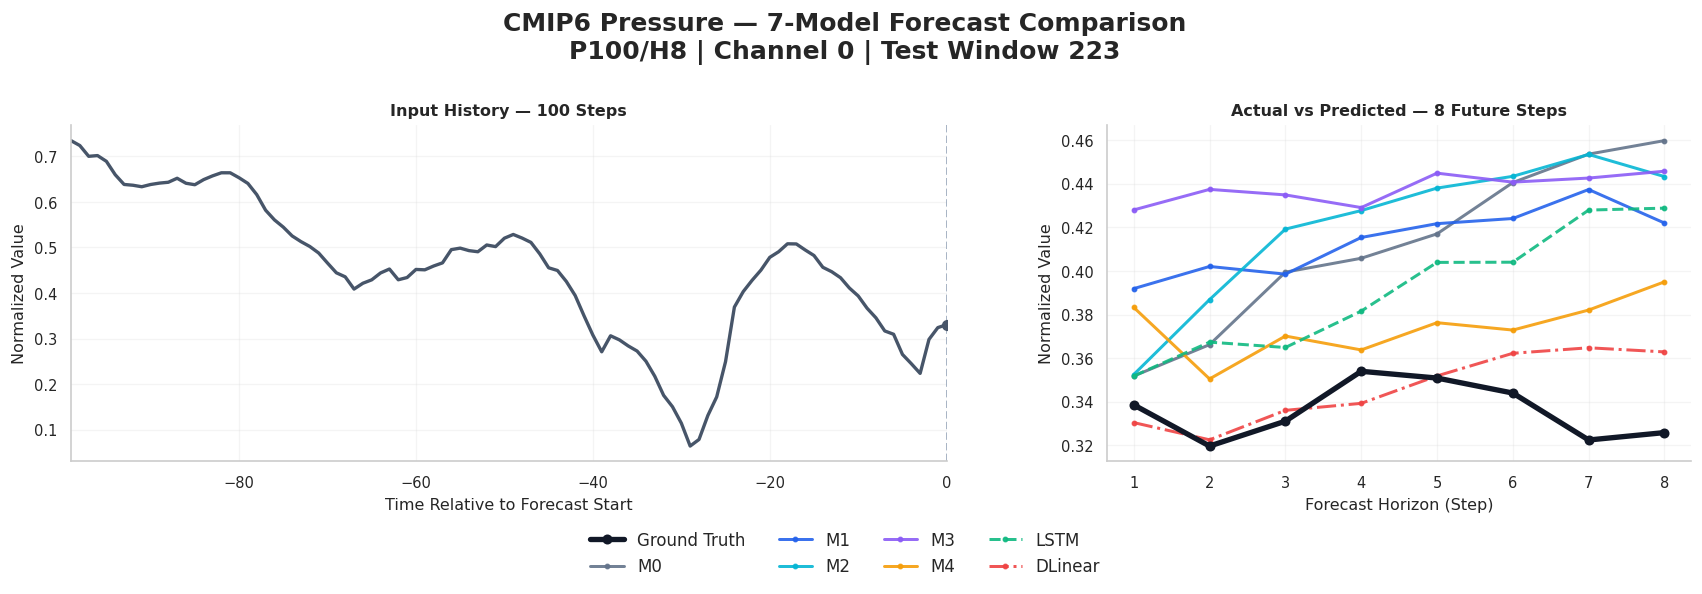

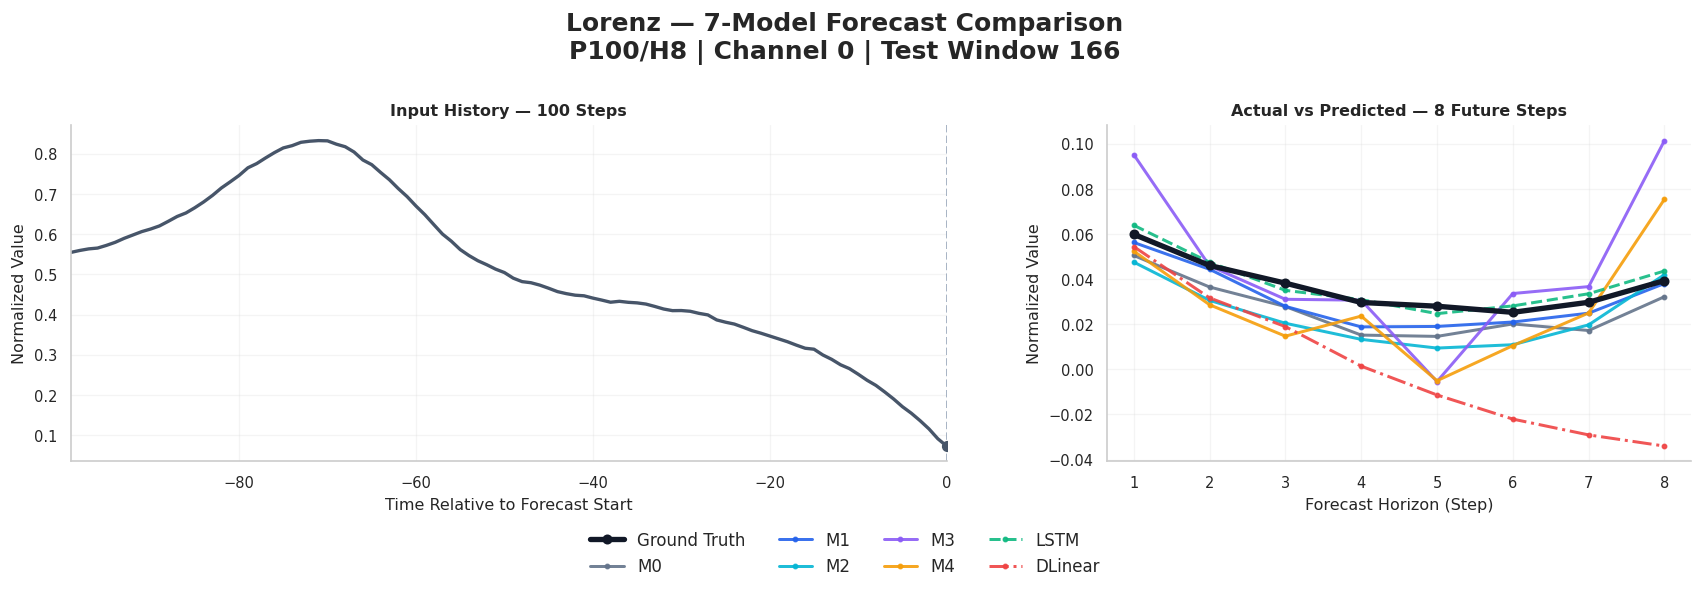


[PASS] Generated 5 forecast comparison figures

SELECTED WINDOW MSE — CHANNEL 0


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0.00948061,0.00849558,0.00818897,0.01056536,0.01472001,0.00230945,0.00164847
Financial,0.00473039,0.00136979,0.00086096,0.00215799,0.00983431,0.00009247,0.00007316
CMIP6 Wind,0.00201948,0.00411988,0.01528551,0.00537340,0.00428191,0.00721465,0.03230620
CMIP6 Pressure,0.00731764,0.00647832,0.00829206,0.01066218,0.00179826,0.00406214,0.00047606
Lorenz,0.00011367,0.00004540,0.00020425,0.00079862,0.00044783,0.00001015,0.00175496


In [5]:
CHANNEL = 0
SAMPLE_POSITION = 4

forecast_plot_records = []

for dataset, dataset_key in DATASET_MAP.items():
    bundle = forecast_data[dataset]

    x = bundle["x"]
    y = bundle["y"]
    predictions = bundle["predictions"]
    indices = bundle["sample_indices"]

    assert SAMPLE_POSITION < len(x)
    assert CHANNEL < x.shape[2]

    history = x[SAMPLE_POSITION, :, CHANNEL]
    actual = y[SAMPLE_POSITION, CHANNEL, :]

    history_steps = np.arange(-LOOKBACK + 1, 1)
    future_steps = np.arange(1, HORIZON + 1)

    fig, axes = plt.subplots(
        1, 2,
        figsize=(15, 5),
        gridspec_kw={"width_ratios": [1.5, 1]},
        constrained_layout=False
    )

    axes[0].plot(
        history_steps,
        history,
        color="#475569",
        linewidth=2,
        label="Observed History"
    )

    axes[0].axvline(
        0,
        color="#94A3B8",
        linestyle="--",
        alpha=0.8
    )

    axes[0].scatter(
        [0],
        [history[-1]],
        color="#475569",
        s=35,
        zorder=5
    )

    axes[0].set_title("Input History — 100 Steps")
    axes[0].set_xlabel("Time Relative to Forecast Start")
    axes[0].set_ylabel("Normalized Value")
    axes[0].set_xlim(-LOOKBACK + 1, 0)
    axes[0].grid(alpha=0.2)

    axes[1].plot(
        future_steps,
        actual,
        color="#111827",
        linewidth=3.2,
        marker="o",
        markersize=5,
        label="Ground Truth",
        zorder=10
    )

    for model in MODEL_ORDER:
        predicted = predictions[model][
            SAMPLE_POSITION, CHANNEL, :
        ]

        linestyle = {
            "LSTM": "--",
            "DLinear": "-."
        }.get(model, "-")

        axes[1].plot(
            future_steps,
            predicted,
            color=MODEL_COLORS[model],
            linewidth=1.8,
            linestyle=linestyle,
            marker=".",
            markersize=5,
            alpha=0.9,
            label=model
        )

        forecast_plot_records.append({
            "dataset": dataset,
            "model": model,
            "sample_position": SAMPLE_POSITION,
            "test_window_index": int(
                indices[SAMPLE_POSITION]
            ),
            "channel": CHANNEL,
            "window_mse": float(
                np.mean((predicted - actual) ** 2)
            ),
            "window_mae": float(
                np.mean(np.abs(predicted - actual))
            )
        })

    axes[1].set_title("Actual vs Predicted — 8 Future Steps")
    axes[1].set_xlabel("Forecast Horizon (Step)")
    axes[1].set_ylabel("Normalized Value")
    axes[1].set_xticks(future_steps)
    axes[1].grid(alpha=0.2)

    handles, labels = axes[1].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.015),
        ncol=4,
        fontsize=10,
        frameon=False
    )

    fig.suptitle(
        f"{dataset} — 7-Model Forecast Comparison\n"
        f"P100/H8 | Channel {CHANNEL} | "
        f"Test Window {int(indices[SAMPLE_POSITION])}",
        fontsize=15,
        fontweight="bold",
        y=0.98
    )

    fig.subplots_adjust(
        left=0.07,
        right=0.97,
        bottom=0.23,
        top=0.79,
        wspace=0.22
    )

    output_png = (
        FIGURES_DIR
        / f"fig01_actual_vs_pred_{dataset_key}.png"
    )

    output_pdf = output_png.with_suffix(".pdf")

    fig.savefig(
        output_png,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        output_pdf,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

forecast_plot_df = pd.DataFrame(forecast_plot_records)

forecast_plot_df.to_csv(
    FIGURES_DIR / "actual_vs_pred_window_metrics.csv",
    index=False
)

print("\n[PASS] Generated 5 forecast comparison figures")

print("\nSELECTED WINDOW MSE — CHANNEL 0")
display(
    forecast_plot_df.pivot(
        index="dataset",
        columns="model",
        values="window_mse"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).style.format("{:.8f}")
)


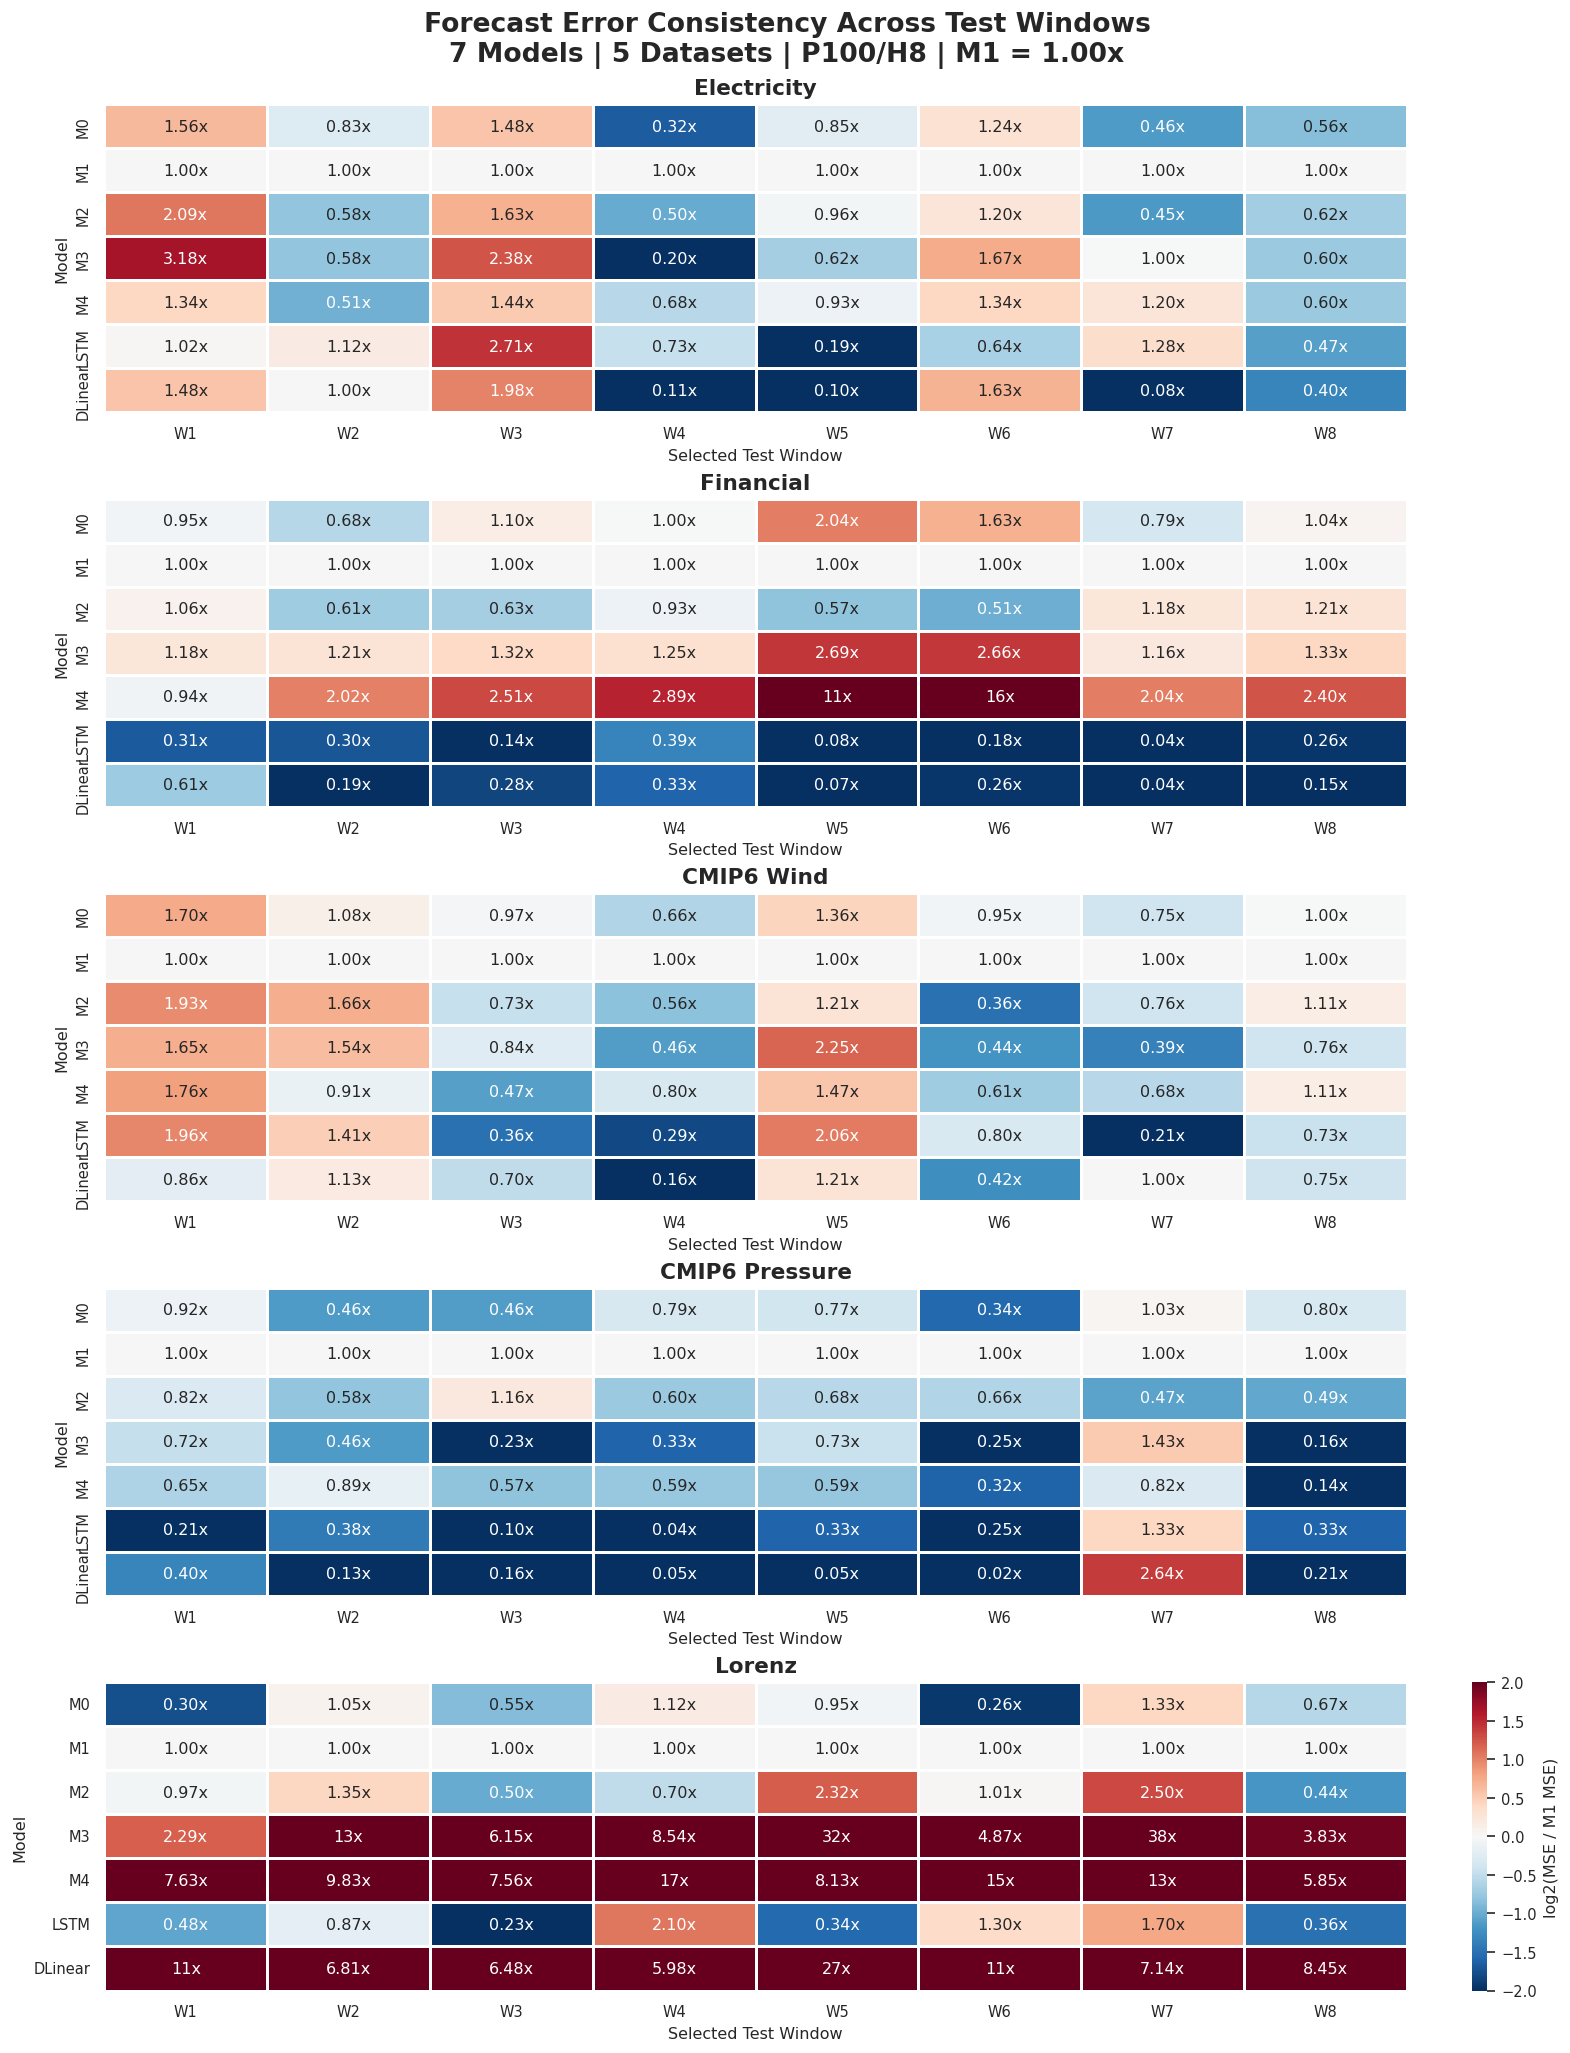

WINDOW-WISE MODEL PERFORMANCE


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0.73x,1.00x,0.76x,0.81x,0.87x,0.85x,0.54x
Financial,1.05x,1.00x,0.94x,1.41x,3.46x,0.24x,0.22x
CMIP6 Wind,0.85x,1.00x,0.86x,0.80x,0.83x,0.67x,0.53x
CMIP6 Pressure,0.65x,1.00x,0.76x,0.33x,0.47x,0.23x,0.22x
Lorenz,0.64x,1.00x,0.92x,8.76x,8.46x,0.60x,9.78x



NUMBER OF WINDOWS WON BY EACH MODEL


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0,2,0,0,1,1,4
Financial,0,0,0,0,0,4,4
CMIP6 Wind,0,1,1,0,1,3,2
CMIP6 Pressure,0,0,1,0,1,3,3
Lorenz,2,1,1,0,0,4,0



WINS AGAINST M1 (OUT OF 8 WINDOWS)


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,5,0,5,5,4,4,4
Financial,4,0,5,0,1,8,8
CMIP6 Wind,5,0,4,5,5,5,5
CMIP6 Pressure,7,0,7,7,8,7,7
Lorenz,5,0,4,0,0,5,0



[PASS] Window-wise forecasting analysis completed


In [6]:
window_records = []

for dataset in DATASETS:
    bundle = forecast_data[dataset]

    actual = bundle["y"].astype(np.float64)
    predictions = bundle["predictions"]
    indices = bundle["sample_indices"]

    for position in range(len(actual)):
        target = actual[position]

        for model in MODEL_ORDER:
            pred = predictions[model][position].astype(
                np.float64
            )

            error = pred - target

            window_records.append({
                "dataset": dataset,
                "model": model,
                "sample_position": position,
                "test_window_index": int(indices[position]),
                "window_mse": float(np.mean(error ** 2)),
                "window_mae": float(np.mean(np.abs(error)))
            })

window_errors_df = pd.DataFrame(window_records)

assert len(window_errors_df) == 5 * 7 * 8

reference = (
    window_errors_df[
        window_errors_df["model"] == "M1"
    ]
    .set_index(["dataset", "sample_position"])[
        "window_mse"
    ]
)

window_errors_df["relative_mse_vs_m1"] = [
    mse / max(
        reference.loc[(dataset, position)],
        1e-15
    )
    for dataset, position, mse in zip(
        window_errors_df["dataset"],
        window_errors_df["sample_position"],
        window_errors_df["window_mse"]
    )
]

window_errors_df["better_than_m1"] = (
    window_errors_df["relative_mse_vs_m1"] < 1
)

fig, axes = plt.subplots(
    5, 1,
    figsize=(13, 17),
    constrained_layout=True
)

for i, dataset in enumerate(DATASETS):
    subset = window_errors_df[
        window_errors_df["dataset"] == dataset
    ]

    ratios = subset.pivot(
        index="model",
        columns="sample_position",
        values="relative_mse_vs_m1"
    ).reindex(
        index=MODEL_ORDER,
        columns=range(8)
    )

    log_ratios = np.log2(
        np.maximum(ratios, 1e-15)
    )

    labels = ratios.map(
        lambda v: (
            f"{v:.2f}x" if v < 10
            else f"{v:.0f}x"
        )
    )

    sns.heatmap(
        log_ratios,
        annot=labels,
        fmt="",
        cmap="RdBu_r",
        center=0,
        vmin=-2,
        vmax=2,
        linewidths=0.7,
        linecolor="white",
        cbar=(i == 4),
        cbar_kws={
            "label": "log2(MSE / M1 MSE)"
        } if i == 4 else None,
        ax=axes[i]
    )

    axes[i].set_title(
        dataset,
        fontsize=13,
        fontweight="bold"
    )

    axes[i].set_xlabel("Selected Test Window")
    axes[i].set_ylabel("Model")

    axes[i].set_xticklabels(
        [f"W{j+1}" for j in range(8)],
        rotation=0
    )

fig.suptitle(
    "Forecast Error Consistency Across Test Windows\n"
    "7 Models | 5 Datasets | P100/H8 | M1 = 1.00x",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig02_window_consistency.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig02_window_consistency.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

window_winners = (
    window_errors_df.loc[
        window_errors_df.groupby(
            ["dataset", "sample_position"]
        )["window_mse"].idxmin()
    ]
    [["dataset", "sample_position", "model"]]
    .rename(columns={"model": "winner"})
)

win_counts = (
    window_winners.groupby(
        ["dataset", "winner"]
    )
    .size()
    .rename("best_window_count")
    .reset_index()
)

consistency_summary = (
    window_errors_df.groupby(
        ["dataset", "model"],
        as_index=False
    )
    .agg(
        windows=("window_mse", "size"),
        mean_mse=("window_mse", "mean"),
        median_window_mse=("window_mse", "median"),
        wins_vs_m1=("better_than_m1", "sum")
    )
)

consistency_summary = consistency_summary.merge(
    win_counts,
    left_on=["dataset", "model"],
    right_on=["dataset", "winner"],
    how="left"
).drop(columns=["winner"])

consistency_summary["best_window_count"] = (
    consistency_summary["best_window_count"]
    .fillna(0)
    .astype(int)
)

m1_mean = (
    consistency_summary[
        consistency_summary["model"] == "M1"
    ].set_index("dataset")["mean_mse"]
)

consistency_summary["mean_mse_ratio_vs_m1"] = [
    mse / m1_mean.loc[dataset]
    for dataset, mse in zip(
        consistency_summary["dataset"],
        consistency_summary["mean_mse"]
    )
]

print("WINDOW-WISE MODEL PERFORMANCE")
display(
    consistency_summary[
        [
            "dataset",
            "model",
            "mean_mse_ratio_vs_m1",
            "wins_vs_m1",
            "best_window_count"
        ]
    ].pivot(
        index="dataset",
        columns="model",
        values="mean_mse_ratio_vs_m1"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).style.format("{:.2f}x")
)

print("\nNUMBER OF WINDOWS WON BY EACH MODEL")
display(
    consistency_summary.pivot(
        index="dataset",
        columns="model",
        values="best_window_count"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).fillna(0).astype(int)
)

print("\nWINS AGAINST M1 (OUT OF 8 WINDOWS)")
display(
    consistency_summary.pivot(
        index="dataset",
        columns="model",
        values="wins_vs_m1"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).astype(int)
)

window_errors_df.to_csv(
    FIGURES_DIR / "window_level_forecast_errors.csv",
    index=False
)

consistency_summary.to_csv(
    FIGURES_DIR / "window_consistency_summary.csv",
    index=False
)

window_winners.to_csv(
    FIGURES_DIR / "window_winners.csv",
    index=False
)

print("\n[PASS] Window-wise forecasting analysis completed")


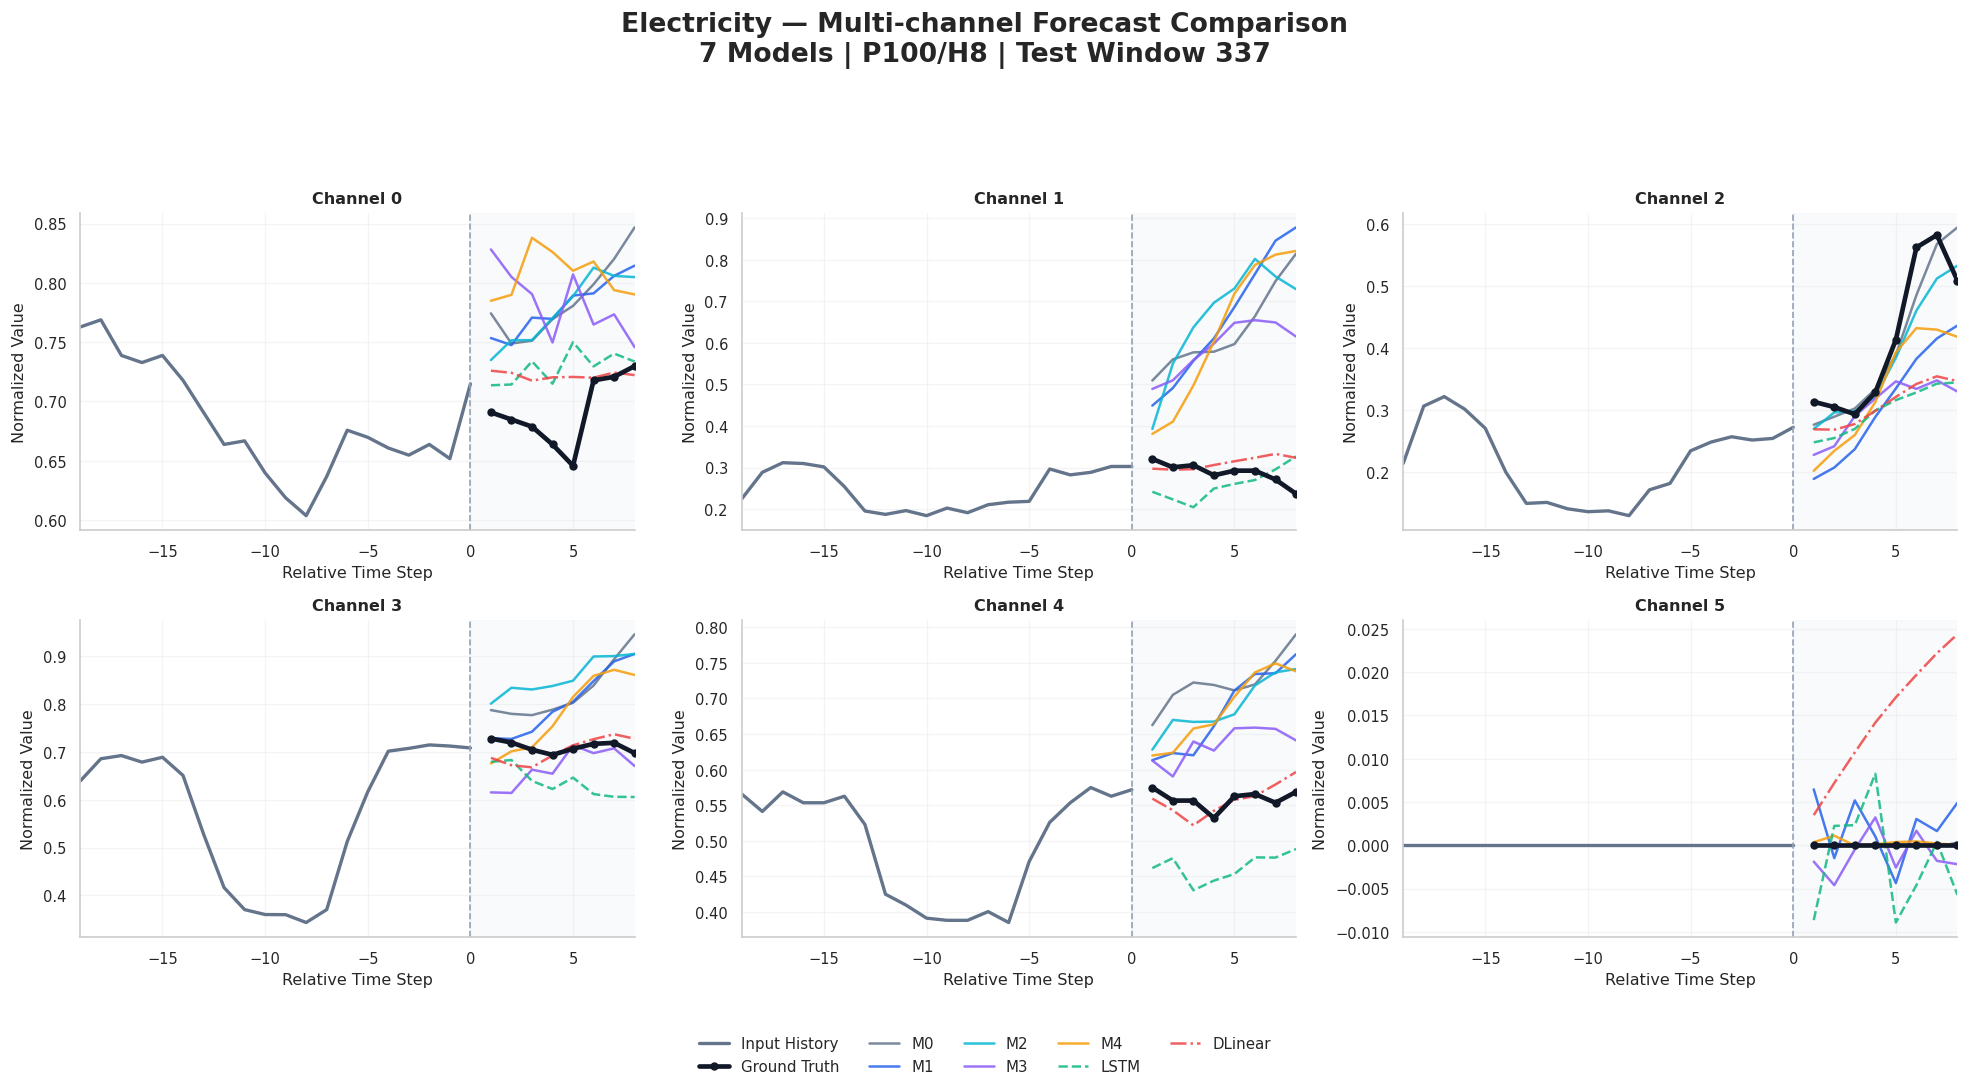

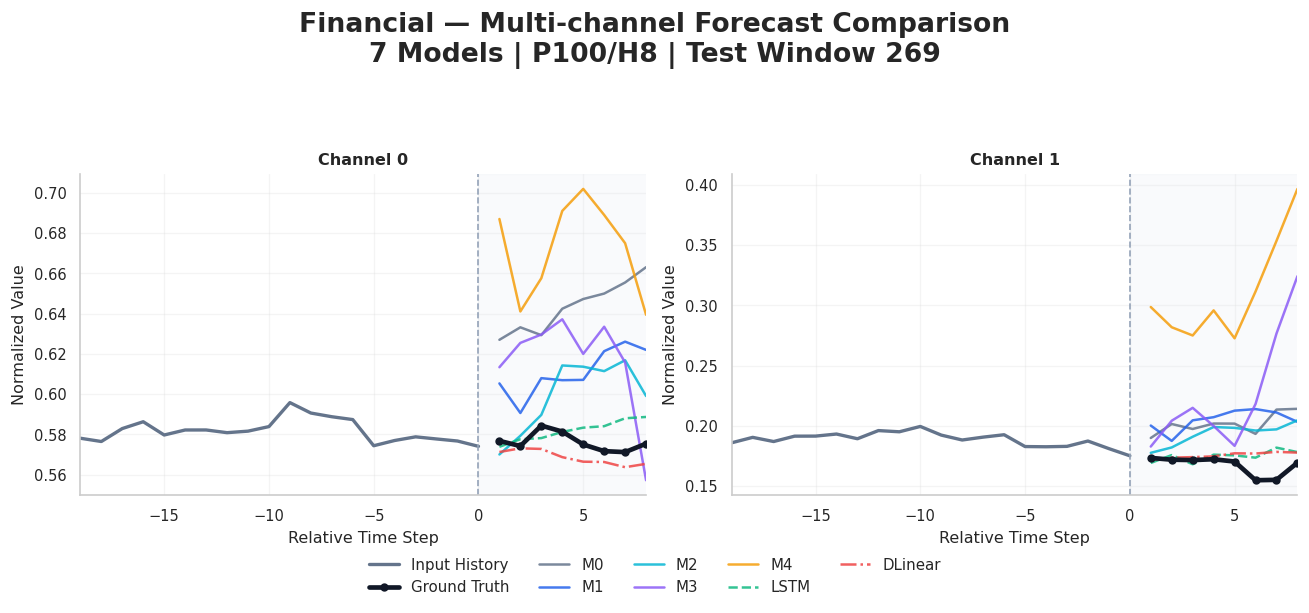

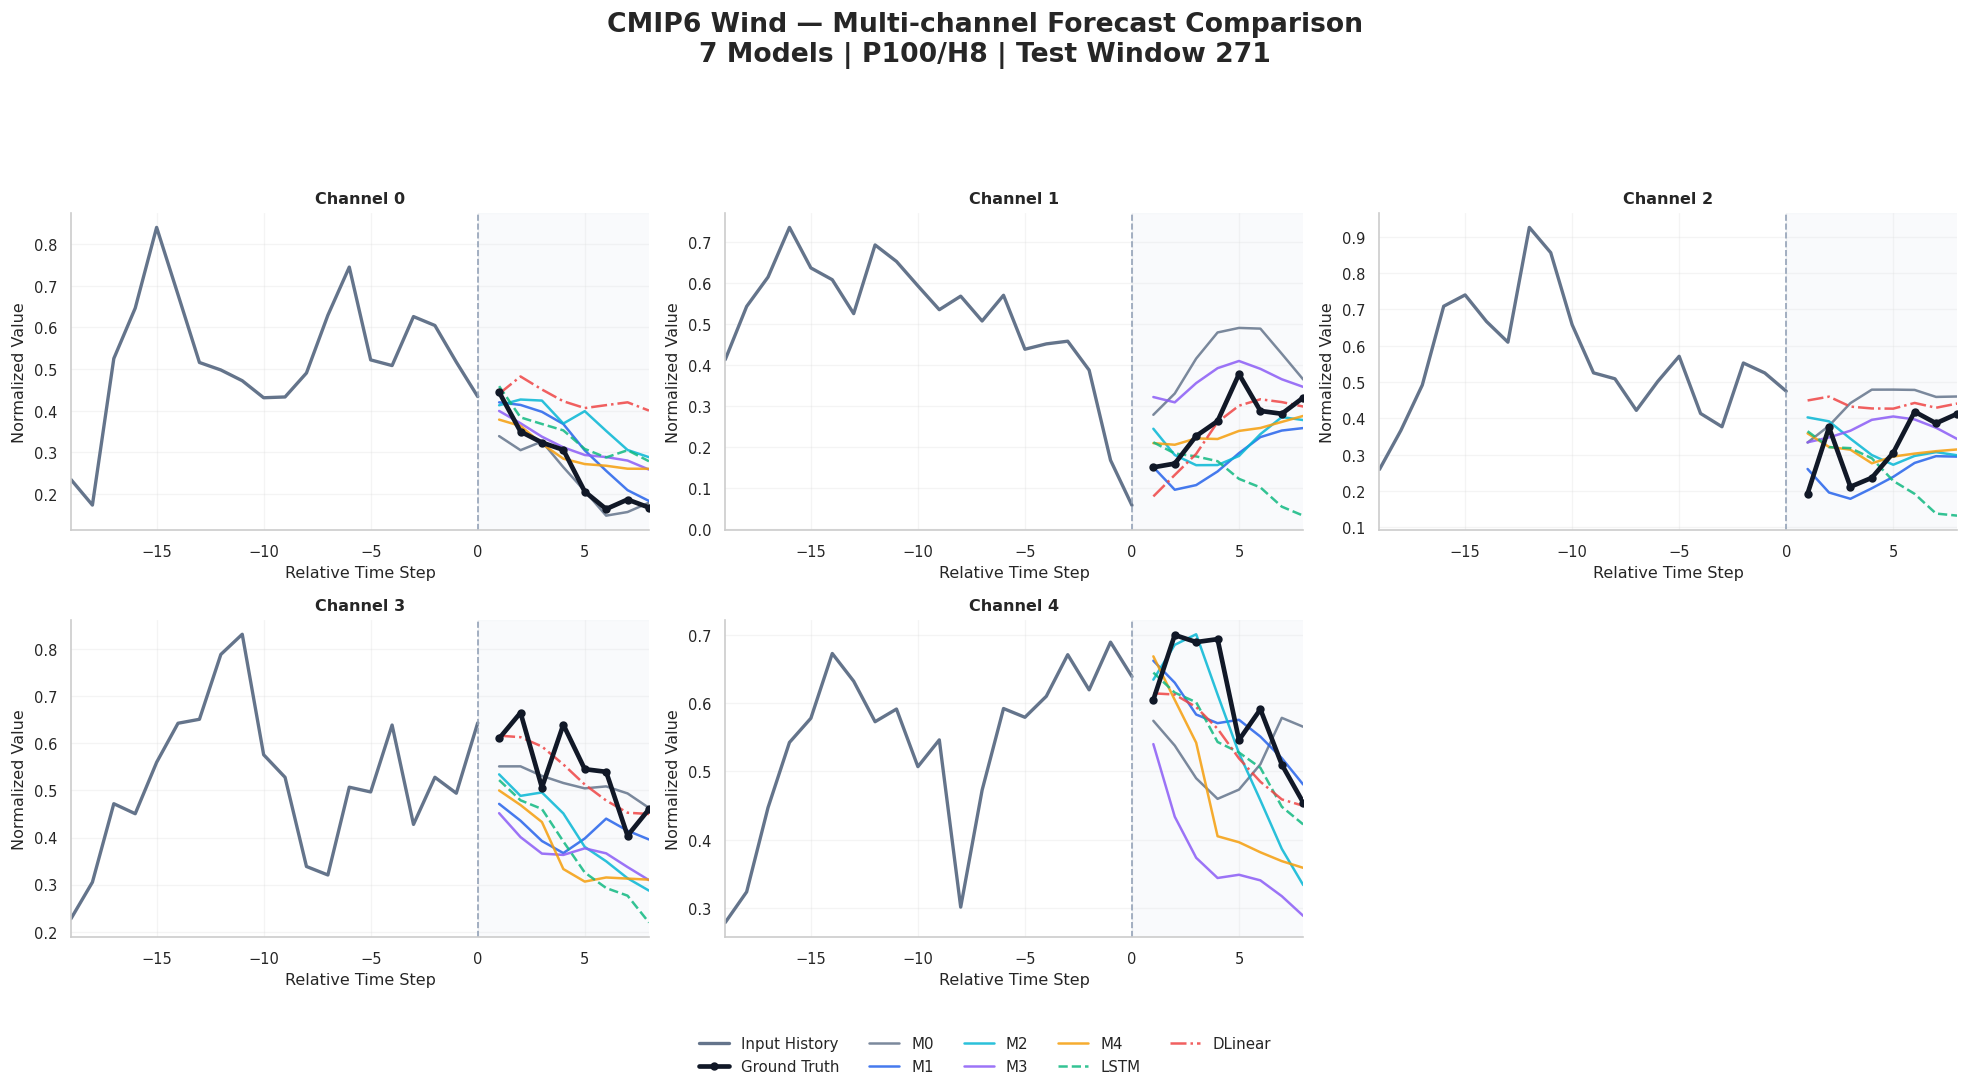

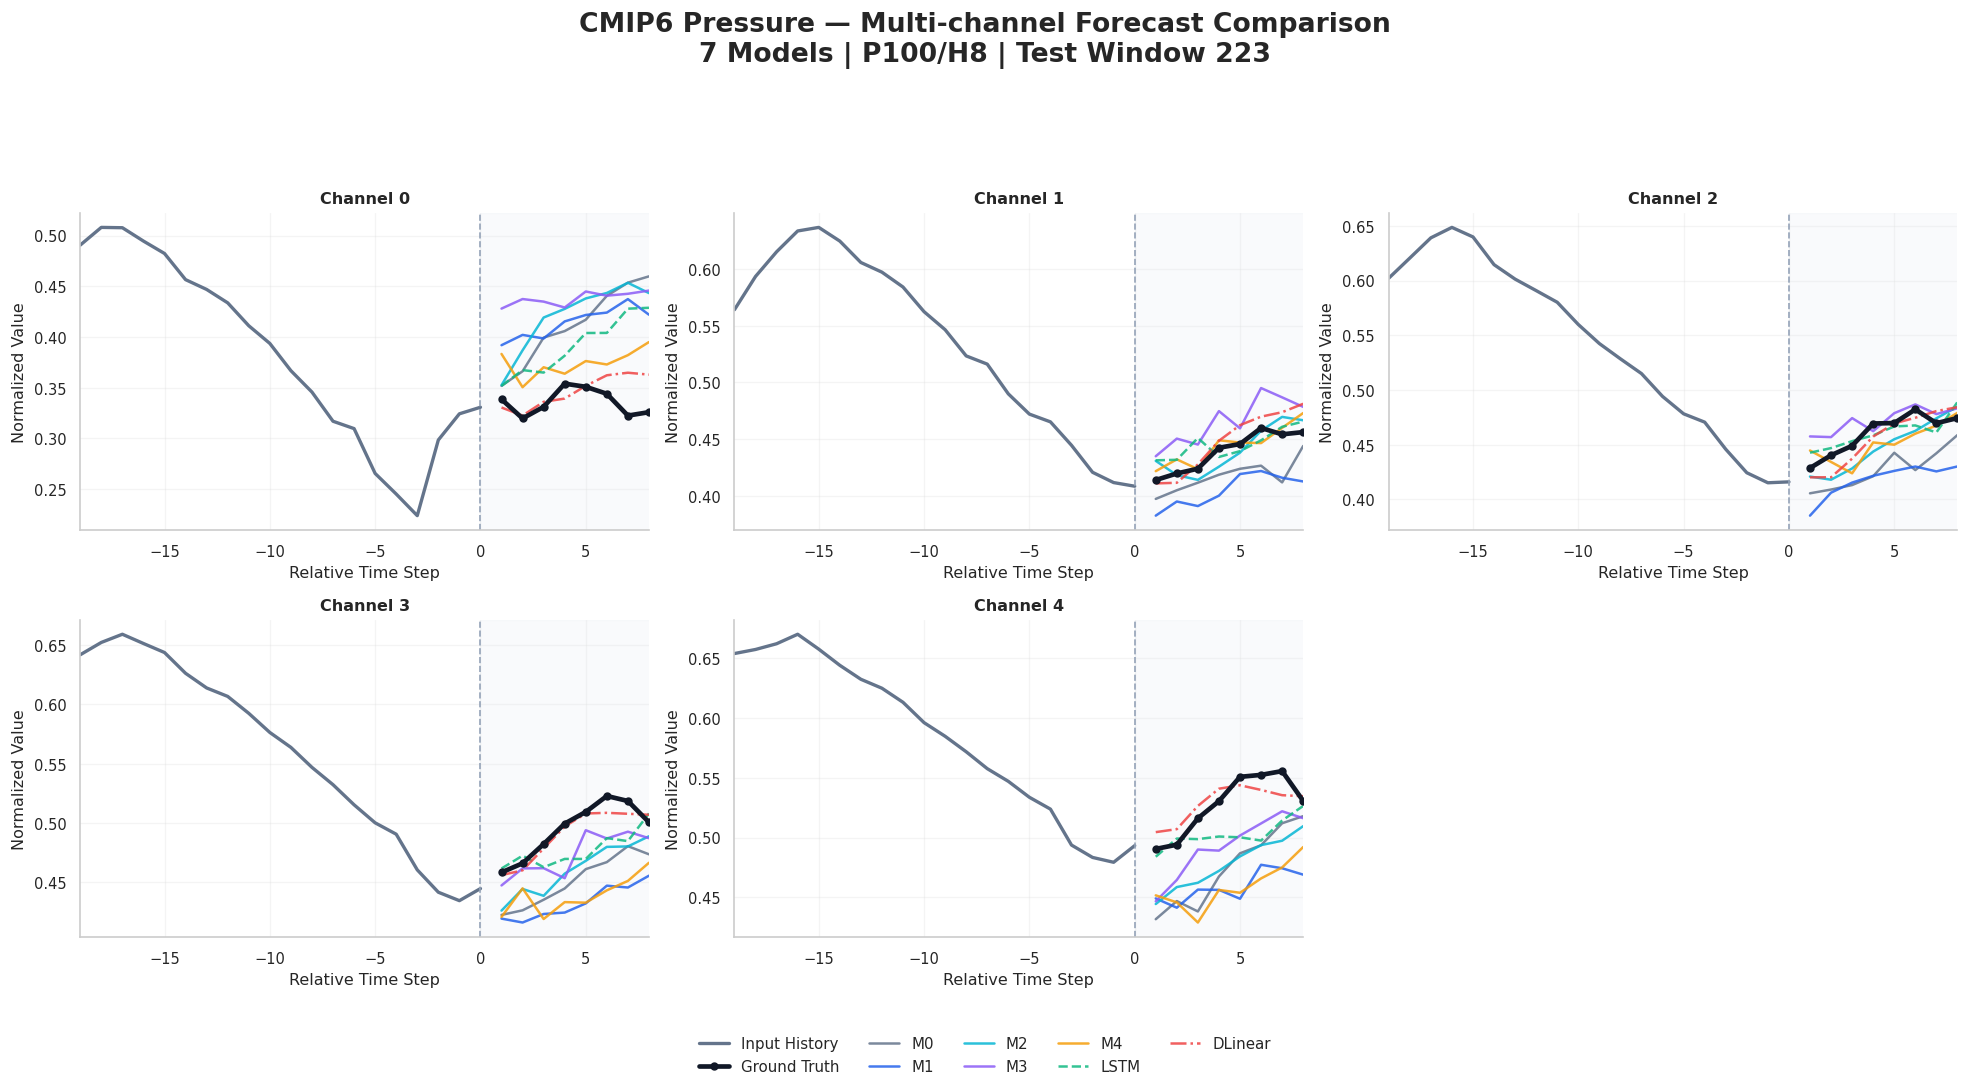

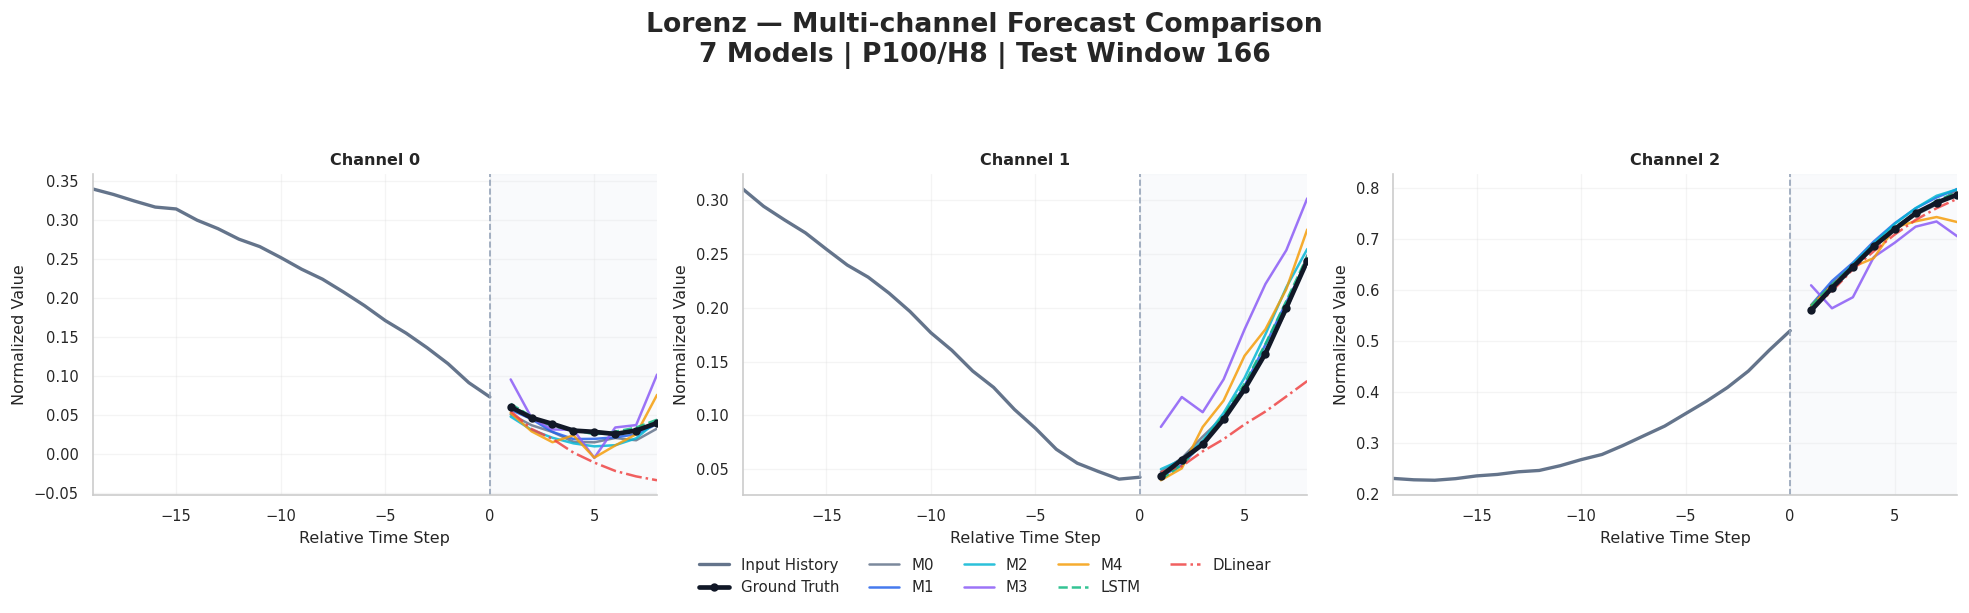


BEST MODEL FOR EACH CHANNEL


channel,0,1,2,3,4,5
dataset,,,,,,
Electricity,DLinear,DLinear,M1,M4,DLinear,M2
Financial,LSTM,DLinear,NaN,NaN,NaN,NaN
CMIP6 Wind,LSTM,DLinear,DLinear,DLinear,DLinear,NaN
CMIP6 Pressure,DLinear,LSTM,LSTM,LSTM,DLinear,NaN
Lorenz,LSTM,M0,LSTM,NaN,NaN,NaN



NUMBER OF CHANNELS WON BY MODEL


best_model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0,1,1,0,1,0,3
Financial,0,0,0,0,0,1,1
CMIP6 Wind,0,0,0,0,0,1,4
CMIP6 Pressure,0,0,0,0,0,3,2
Lorenz,1,0,0,0,0,2,0



CHANNEL-LEVEL MSE RELATIVE TO M1



[PASS] Multi-channel forecasting analysis completed


In [7]:
from math import ceil

SAMPLE_POSITION = 4
HISTORY_DISPLAY = 20

channel_records = []
channel_winner_records = []

for dataset, dataset_key in DATASET_MAP.items():
    bundle = forecast_data[dataset]

    x = bundle["x"]
    y = bundle["y"]
    predictions = bundle["predictions"]
    indices = bundle["sample_indices"]

    n_samples, channels, horizon = y.shape

    assert n_samples == 8
    assert horizon == HORIZON
    assert SAMPLE_POSITION < n_samples

    ncols = min(3, channels)
    nrows = ceil(channels / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5.5 * ncols, 4.1 * nrows + 1),
        squeeze=False
    )

    axes_flat = axes.flatten()

    history_steps = np.arange(
        -HISTORY_DISPLAY + 1, 1
    )
    future_steps = np.arange(1, HORIZON + 1)

    for channel in range(channels):
        ax = axes_flat[channel]

        history = x[
            SAMPLE_POSITION,
            -HISTORY_DISPLAY:,
            channel
        ]

        actual = y[
            SAMPLE_POSITION,
            channel,
            :
        ]

        ax.plot(
            history_steps,
            history,
            color="#64748B",
            linewidth=2,
            label="Input History"
        )

        ax.plot(
            future_steps,
            actual,
            color="#111827",
            linewidth=2.8,
            marker="o",
            markersize=4,
            label="Ground Truth",
            zorder=10
        )

        ax.axvspan(
            0,
            HORIZON + 0.5,
            color="#E2E8F0",
            alpha=0.2
        )

        ax.axvline(
            0,
            color="#94A3B8",
            linestyle="--",
            linewidth=1
        )

        channel_errors = {}

        for model in MODEL_ORDER:
            pred = predictions[model][
                SAMPLE_POSITION,
                channel,
                :
            ]

            ax.plot(
                future_steps,
                pred,
                color=MODEL_COLORS[model],
                linestyle=(
                    "--" if model == "LSTM"
                    else "-." if model == "DLinear"
                    else "-"
                ),
                linewidth=1.5,
                alpha=0.85,
                label=model
            )

            all_errors = (
                predictions[model][:, channel, :].astype(
                    np.float64
                )
                - y[:, channel, :].astype(
                    np.float64
                )
            )

            mse = float(np.mean(all_errors ** 2))
            mae = float(np.mean(np.abs(all_errors)))

            channel_errors[model] = mse

            channel_records.append({
                "dataset": dataset,
                "model": model,
                "channel": channel,
                "n_windows": n_samples,
                "mse": mse,
                "mae": mae
            })

        best_model = min(
            channel_errors,
            key=channel_errors.get
        )

        channel_winner_records.append({
            "dataset": dataset,
            "channel": channel,
            "best_model": best_model,
            "best_mse": channel_errors[best_model]
        })

        ax.set_title(
            f"Channel {channel}",
            fontweight="bold"
        )

        ax.set_xlabel("Relative Time Step")
        ax.set_ylabel("Normalized Value")
        ax.set_xlim(-HISTORY_DISPLAY + 1, HORIZON)
        ax.grid(alpha=0.2)

    for ax in axes_flat[channels:]:
        ax.axis("off")

    handles, labels = axes_flat[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.015),
        ncol=5,
        fontsize=9,
        frameon=False
    )

    fig.suptitle(
        f"{dataset} — Multi-channel Forecast Comparison\n"
        f"7 Models | P100/H8 | Test Window {int(indices[SAMPLE_POSITION])}",
        fontsize=16,
        fontweight="bold",
        y=0.99
    )

    fig.tight_layout(
        rect=[0, 0.09, 1, 0.91]
    )

    fig.savefig(
        FIGURES_DIR / f"fig03_multichannel_{dataset_key}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        FIGURES_DIR / f"fig03_multichannel_{dataset_key}.pdf",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

channel_df = pd.DataFrame(channel_records)
channel_winners_df = pd.DataFrame(channel_winner_records)

m1_channel_reference = (
    channel_df[channel_df["model"] == "M1"]
    .set_index(["dataset", "channel"])["mse"]
)

channel_df["relative_mse_vs_m1"] = [
    mse / max(
        m1_channel_reference.loc[(dataset, channel)],
        1e-15
    )
    for dataset, channel, mse in zip(
        channel_df["dataset"],
        channel_df["channel"],
        channel_df["mse"]
    )
]

channel_df["better_than_m1"] = (
    channel_df["relative_mse_vs_m1"] < 1
)

channel_win_counts = (
    channel_winners_df
    .groupby(["dataset", "best_model"])
    .size()
    .rename("channels_won")
    .reset_index()
)

print("\nBEST MODEL FOR EACH CHANNEL")
display(
    channel_winners_df.pivot(
        index="dataset",
        columns="channel",
        values="best_model"
    ).reindex(index=DATASETS)
)

print("\nNUMBER OF CHANNELS WON BY MODEL")
display(
    channel_win_counts.pivot(
        index="dataset",
        columns="best_model",
        values="channels_won"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).fillna(0).astype(int)
)

print("\nCHANNEL-LEVEL MSE RELATIVE TO M1")
display(
    channel_df.pivot_table(
        index=["dataset", "channel"],
        columns="model",
        values="relative_mse_vs_m1"
    ).reindex(
        columns=MODEL_ORDER
    ).style.format("{:.2f}x")
)

channel_df.to_csv(
    FIGURES_DIR / "channel_forecast_metrics_8windows.csv",
    index=False
)

channel_winners_df.to_csv(
    FIGURES_DIR / "channel_best_models.csv",
    index=False
)

channel_win_counts.to_csv(
    FIGURES_DIR / "channel_winner_counts.csv",
    index=False
)

print("\n[PASS] Multi-channel forecasting analysis completed")


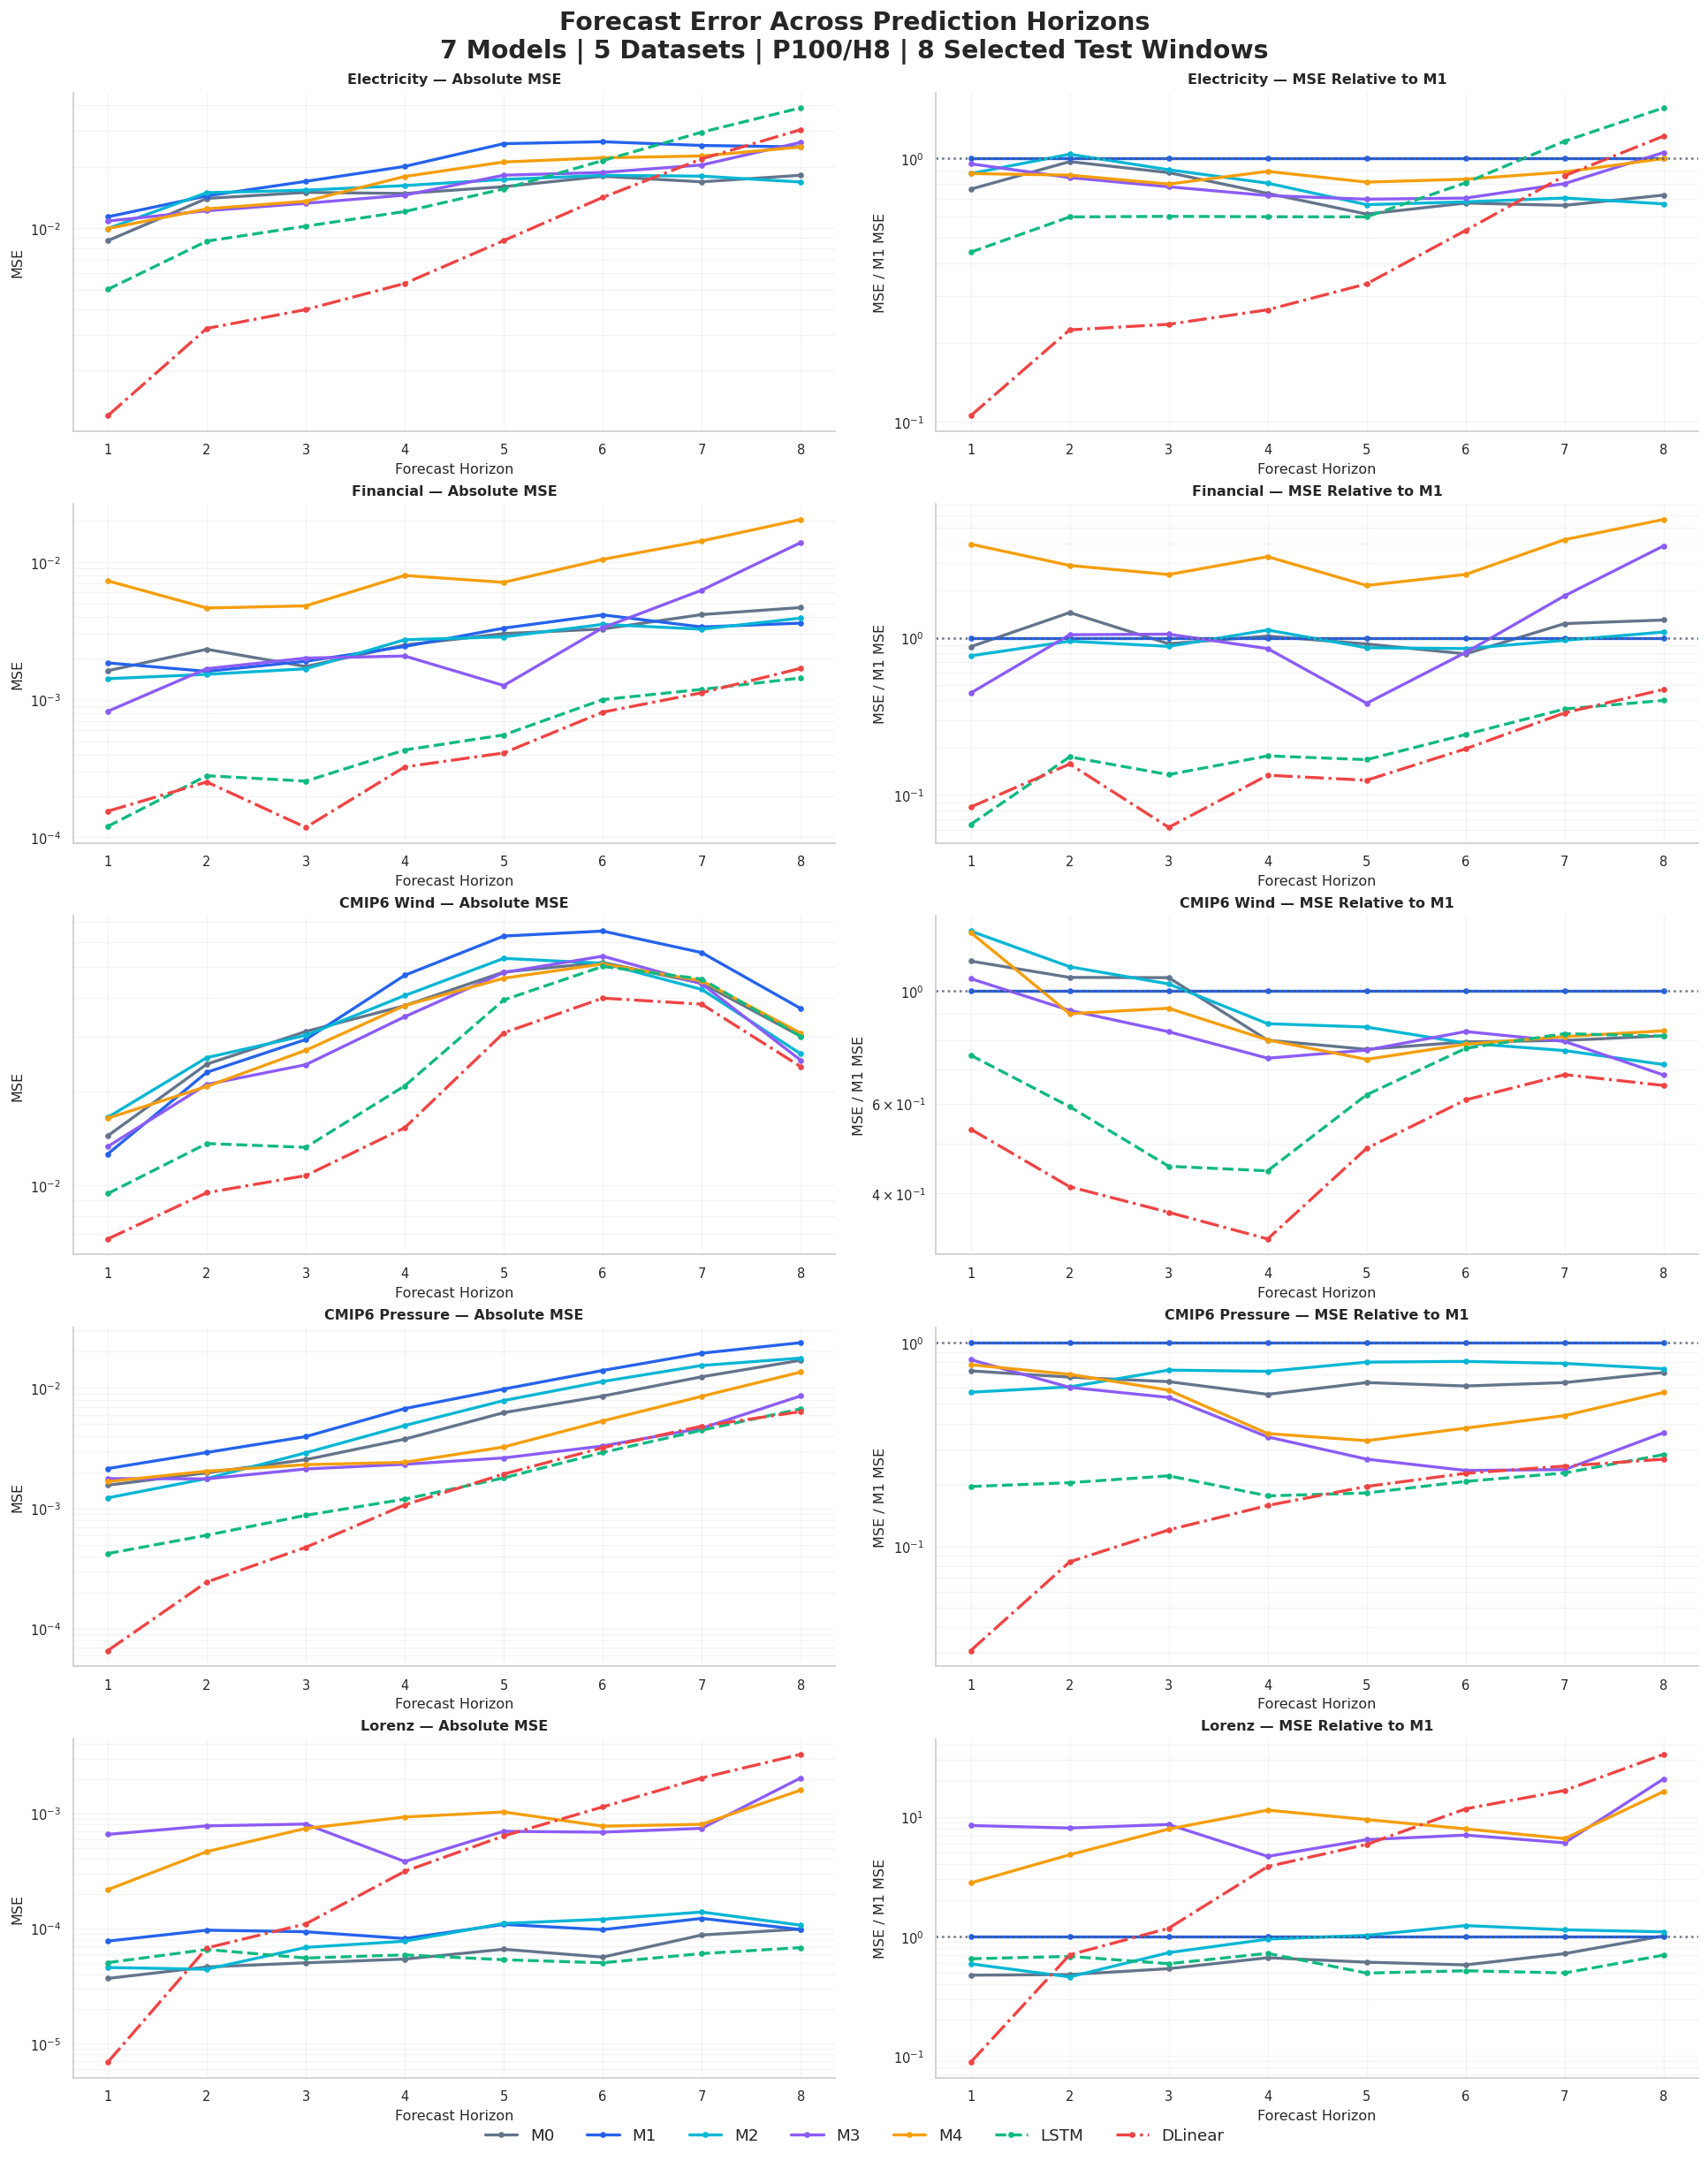

HORIZON ERROR GROWTH — MSE(H8) / MSE(H1)


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,2.09x,2.21x,1.69x,2.43x,2.51x,7.79x,25.37x
Financial,2.88x,1.94x,2.75x,16.79x,2.79x,11.96x,10.90x
CMIP6 Wind,2.08x,2.92x,1.60x,1.89x,1.87x,3.18x,3.56x
CMIP6 Pressure,10.91x,11.11x,14.49x,4.86x,8.13x,15.95x,96.77x
Lorenz,2.69x,1.26x,2.33x,3.10x,7.34x,1.35x,476.52x



MSE AT HORIZON 8


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0.01819255,0.02508015,0.01685904,0.02639535,0.02503435,0.03899463,0.03046956
Financial,0.00466970,0.00359983,0.00391459,0.01383315,0.02037147,0.00143807,0.00169011
CMIP6 Wind,0.03006309,0.03687311,0.02640097,0.02518567,0.03075366,0.03002024,0.02402216
CMIP6 Pressure,0.01699082,0.02379078,0.01771699,0.00859099,0.01355922,0.00671372,0.00636947
Lorenz,0.00009854,0.00009761,0.00010654,0.00203438,0.00159307,0.00006802,0.00326393



BEST MODEL AT HORIZON 8


,best_model_h8,best_mse_h8
dataset,,
Electricity,M2,0.016859
Financial,LSTM,0.001438
CMIP6 Wind,DLinear,0.024022
CMIP6 Pressure,DLinear,0.006369
Lorenz,LSTM,0.000068



[PASS] Horizon-wise forecasting analysis completed


In [8]:
horizon_records = []

for dataset in DATASETS:
    bundle = forecast_data[dataset]

    actual = bundle["y"].astype(np.float64)
    predictions = bundle["predictions"]

    for model in MODEL_ORDER:
        predicted = predictions[model].astype(np.float64)

        assert predicted.shape == actual.shape

        errors = predicted - actual

        for h in range(HORIZON):
            step_errors = errors[:, :, h]

            horizon_records.append({
                "dataset": dataset,
                "model": model,
                "horizon_step": h + 1,
                "mse": float(np.mean(step_errors ** 2)),
                "mae": float(np.mean(np.abs(step_errors))),
                "n_windows": actual.shape[0],
                "n_channels": actual.shape[1]
            })

horizon_df = pd.DataFrame(horizon_records)

assert len(horizon_df) == 5 * 7 * HORIZON
assert horizon_df[["mse", "mae"]].notna().all().all()
assert (horizon_df["mse"] > 0).all().all()

m1_reference = (
    horizon_df[horizon_df["model"] == "M1"]
    .set_index(["dataset", "horizon_step"])["mse"]
)

horizon_df["relative_mse_vs_m1"] = [
    mse / m1_reference.loc[(dataset, h)]
    for dataset, h, mse in zip(
        horizon_df["dataset"],
        horizon_df["horizon_step"],
        horizon_df["mse"]
    )
]

fig, axes = plt.subplots(
    5, 2,
    figsize=(16, 20),
    constrained_layout=True
)

for i, dataset in enumerate(DATASETS):
    subset = horizon_df[
        horizon_df["dataset"] == dataset
    ]

    ax_abs = axes[i, 0]
    ax_rel = axes[i, 1]

    for model in MODEL_ORDER:
        model_data = subset[
            subset["model"] == model
        ].sort_values("horizon_step")

        color = MODEL_COLORS[model]

        linestyle = (
            "--" if model == "LSTM"
            else "-." if model == "DLinear"
            else "-"
        )

        ax_abs.plot(
            model_data["horizon_step"],
            model_data["mse"],
            color=color,
            linestyle=linestyle,
            linewidth=2,
            marker="o",
            markersize=3,
            label=model
        )

        ax_rel.plot(
            model_data["horizon_step"],
            model_data["relative_mse_vs_m1"],
            color=color,
            linestyle=linestyle,
            linewidth=2,
            marker="o",
            markersize=3,
            label=model
        )

    ax_rel.axhline(
        1,
        color="#475569",
        linestyle=":",
        linewidth=1.5,
        alpha=0.8
    )

    ax_abs.set_title(
        f"{dataset} — Absolute MSE",
        fontweight="bold"
    )

    ax_rel.set_title(
        f"{dataset} — MSE Relative to M1",
        fontweight="bold"
    )

    ax_abs.set_ylabel("MSE")
    ax_rel.set_ylabel("MSE / M1 MSE")

    for ax in [ax_abs, ax_rel]:
        ax.set_xlabel("Forecast Horizon")
        ax.set_xticks(range(1, HORIZON + 1))
        ax.set_yscale("log")
        ax.grid(alpha=0.2, which="both")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.015),
    ncol=7,
    fontsize=11,
    frameon=False
)

fig.suptitle(
    "Forecast Error Across Prediction Horizons\n"
    "7 Models | 5 Datasets | P100/H8 | 8 Selected Test Windows",
    fontsize=17,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig04_horizon_error.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig04_horizon_error.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

horizon_summary = (
    horizon_df.groupby(
        ["dataset", "model"],
        as_index=False
    )
    .agg(
        mean_mse=("mse", "mean"),
        mean_mae=("mae", "mean")
    )
)

first_last = horizon_df[
    horizon_df["horizon_step"].isin([1, HORIZON])
].pivot(
    index=["dataset", "model"],
    columns="horizon_step",
    values="mse"
)

first_last.columns = [
    f"mse_h{h}" for h in first_last.columns
]

first_last = first_last.reset_index()

first_last["h8_h1_ratio"] = (
    first_last[f"mse_h{HORIZON}"]
    / first_last["mse_h1"]
)

horizon_summary = horizon_summary.merge(
    first_last,
    on=["dataset", "model"],
    validate="one_to_one"
)

horizon_summary["h8_vs_h1_change_pct"] = (
    100 * (horizon_summary["h8_h1_ratio"] - 1)
)

print("HORIZON ERROR GROWTH — MSE(H8) / MSE(H1)")

display(
    horizon_summary.pivot(
        index="dataset",
        columns="model",
        values="h8_h1_ratio"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).style.format("{:.2f}x")
)

print("\nMSE AT HORIZON 8")

display(
    horizon_df[
        horizon_df["horizon_step"] == HORIZON
    ].pivot(
        index="dataset",
        columns="model",
        values="mse"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).style.format("{:.8f}")
)

print("\nBEST MODEL AT HORIZON 8")

best_h8 = (
    horizon_df[
        horizon_df["horizon_step"] == HORIZON
    ]
    .loc[
        lambda df: df.groupby("dataset")["mse"].idxmin()
    ]
    [["dataset", "model", "mse"]]
    .rename(columns={
        "model": "best_model_h8",
        "mse": "best_mse_h8"
    })
)

display(
    best_h8.set_index("dataset").reindex(DATASETS)
)

horizon_df.to_csv(
    FIGURES_DIR / "horizon_level_forecast_errors.csv",
    index=False
)

horizon_summary.to_csv(
    FIGURES_DIR / "horizon_error_growth_summary.csv",
    index=False
)

best_h8.to_csv(
    FIGURES_DIR / "best_models_at_horizon8.csv",
    index=False
)

print("\n[PASS] Horizon-wise forecasting analysis completed")


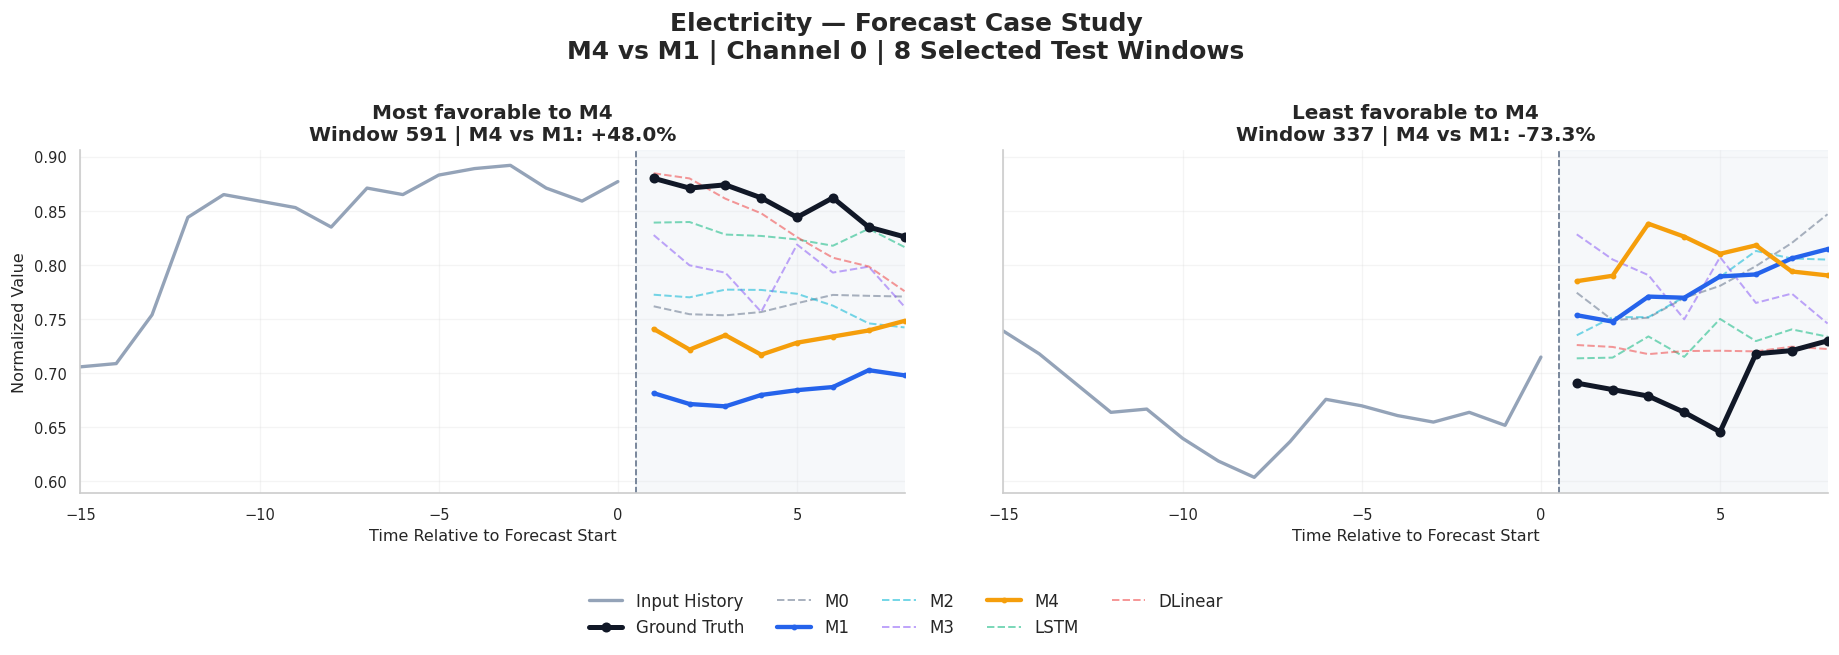

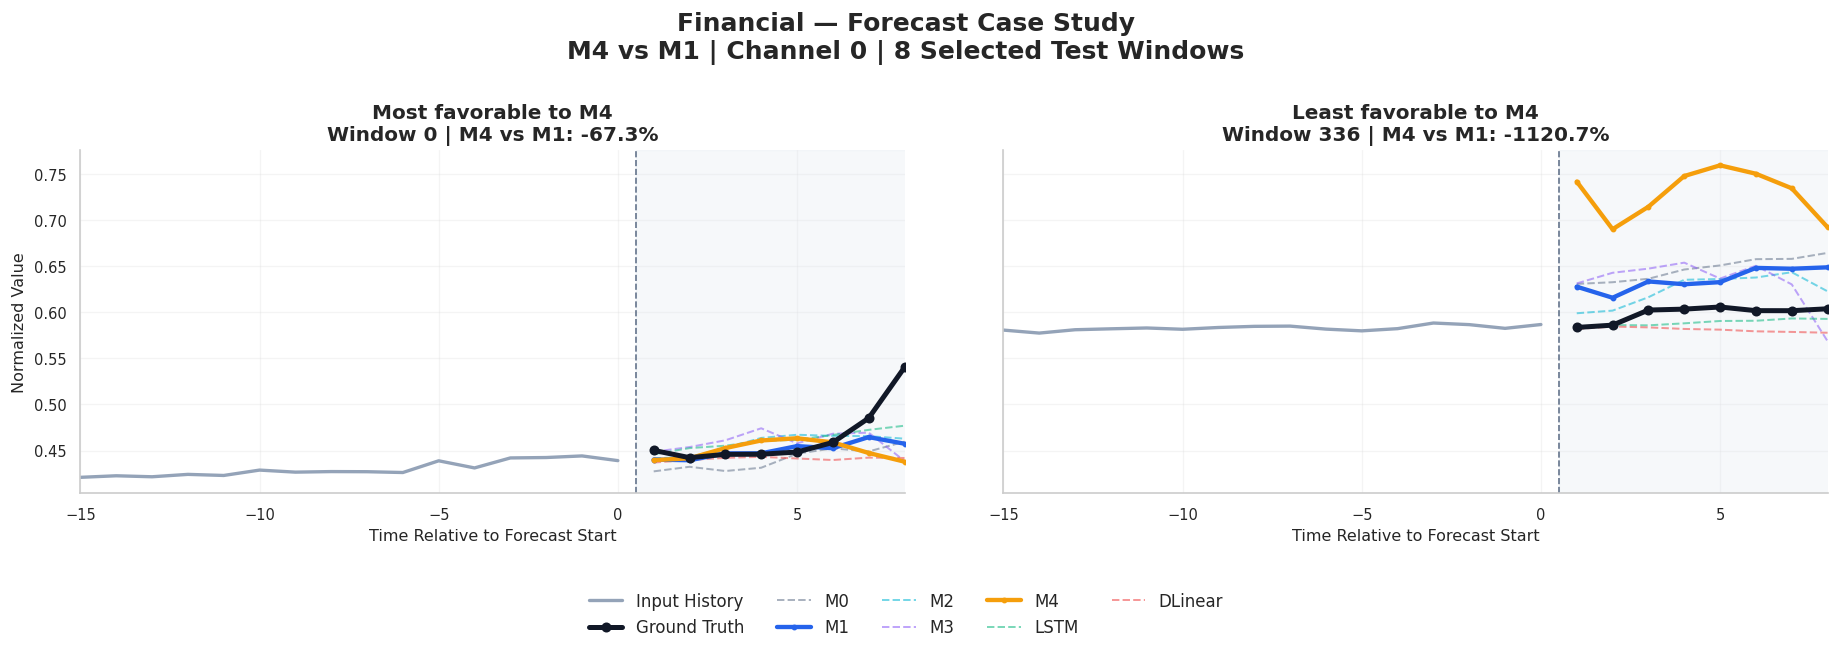

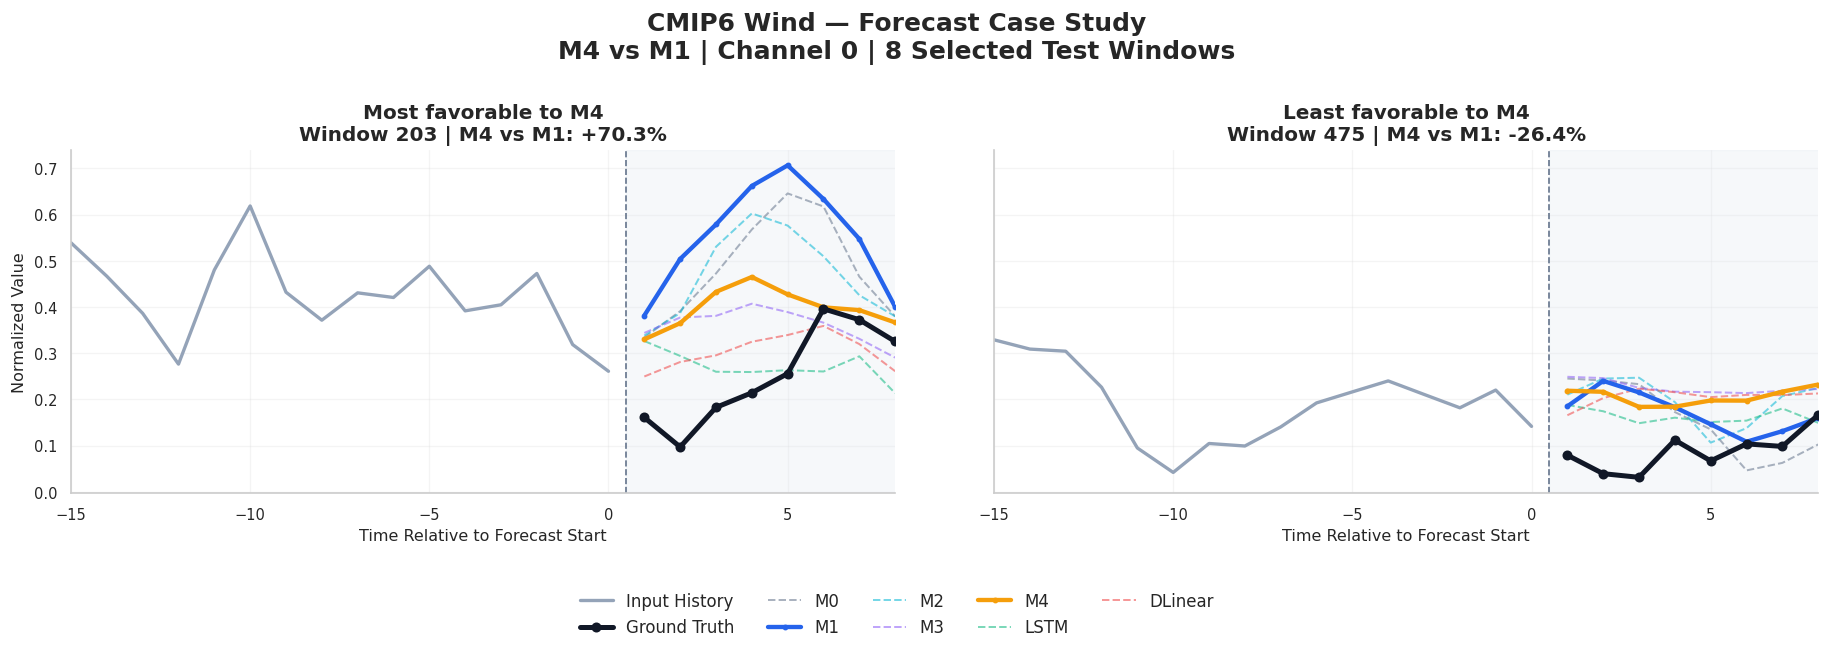

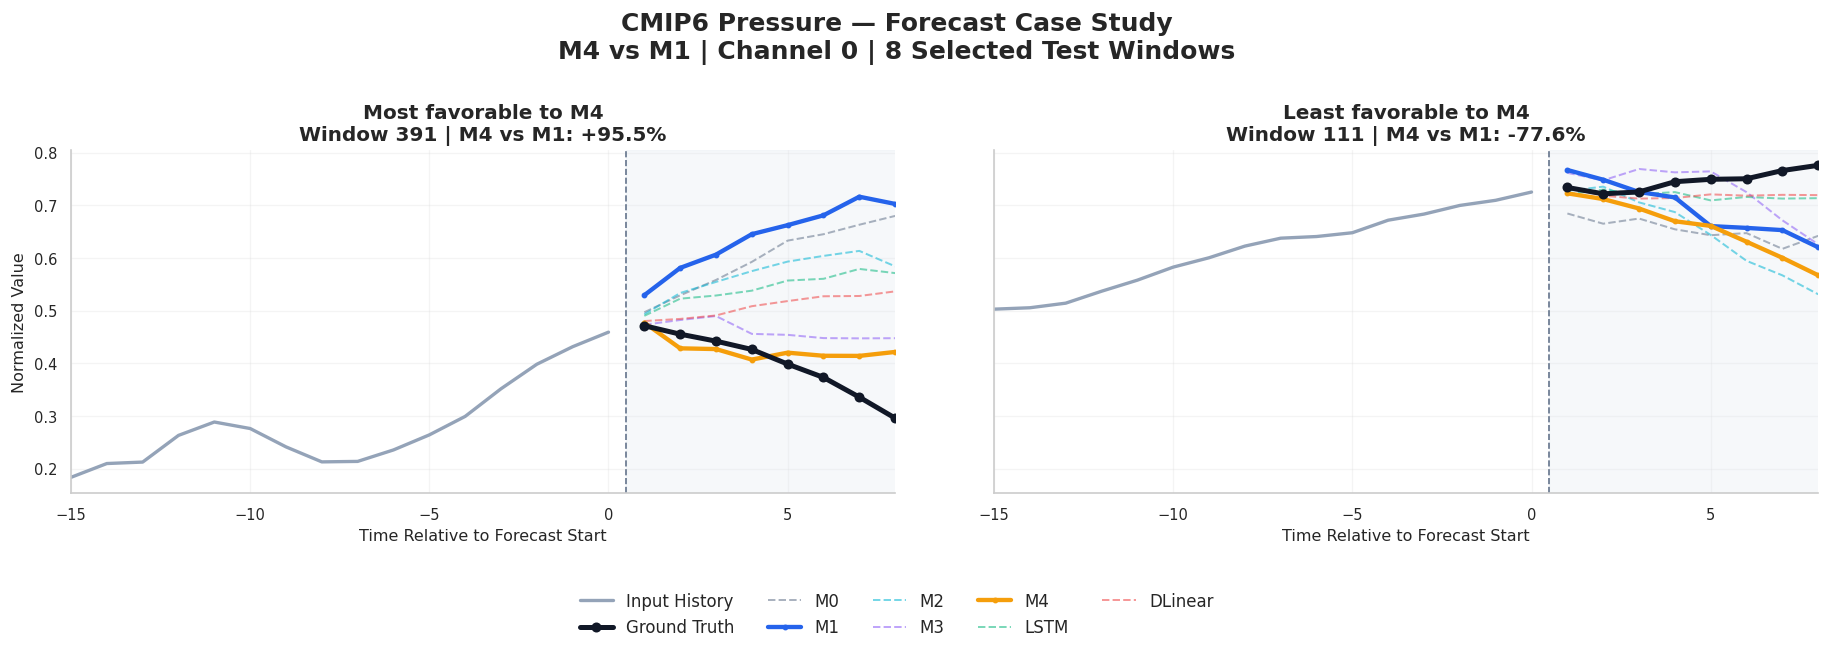

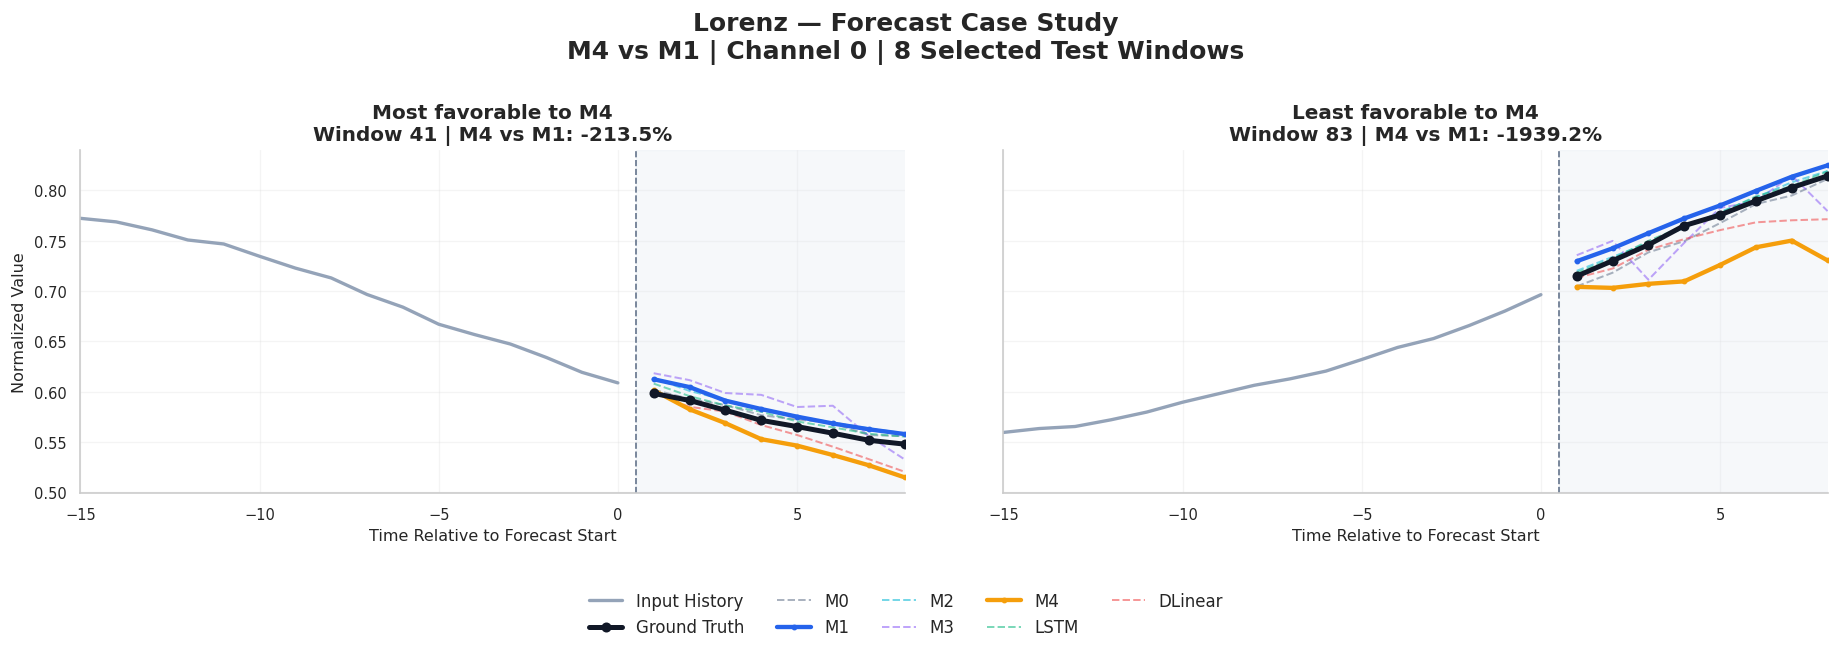

M4 VS M1 — MOST FAVORABLE / LEAST FAVORABLE CASES


,dataset,case_type,test_window_index,mse_m1,mse_m4,improvement_pct,m4_better_than_m1
0,Electricity,Most favorable to M4,591,0.03052890,0.01586982,+48.02%,True
1,Electricity,Least favorable to M4,337,0.00849558,0.01472001,-73.27%,False
2,Financial,Most favorable to M4,0,0.00093804,0.00156891,-67.25%,False
3,Financial,Least favorable to M4,336,0.00144312,0.01761628,-1120.71%,False
4,CMIP6 Wind,Most favorable to M4,203,0.10844517,0.03217350,+70.33%,True
5,CMIP6 Wind,Least favorable to M4,475,0.01222309,0.01545023,-26.40%,False
6,CMIP6 Pressure,Most favorable to M4,391,0.07109561,0.00318192,+95.52%,True
7,CMIP6 Pressure,Least favorable to M4,111,0.00703921,0.01250069,-77.59%,False
8,Lorenz,Most favorable to M4,41,0.00012503,0.00039192,-213.47%,False
9,Lorenz,Least favorable to M4,83,0.00012168,0.00248124,-1939.18%,False



MODEL MSE ON SELECTED CASES



[PASS] Generated 5 best/worst case-study figures


In [9]:
CASE_CHANNEL = 0
HISTORY_DISPLAY = 16

case_records = []
case_metrics = []

for dataset, dataset_key in DATASET_MAP.items():
    bundle = forecast_data[dataset]

    x = bundle["x"]
    y = bundle["y"]
    predictions = bundle["predictions"]
    indices = bundle["sample_indices"]

    assert CASE_CHANNEL < y.shape[1]

    actual_all = y[:, CASE_CHANNEL, :].astype(np.float64)

    mse_by_model = {}

    for model in MODEL_ORDER:
        predicted_all = predictions[model][
            :, CASE_CHANNEL, :
        ].astype(np.float64)

        mse_by_model[model] = np.mean(
            (predicted_all - actual_all) ** 2,
            axis=1
        )

    improvement = (
        mse_by_model["M1"] - mse_by_model["M4"]
    )

    selected_positions = [
        ("Most favorable to M4", int(np.argmax(improvement))),
        ("Least favorable to M4", int(np.argmin(improvement)))
    ]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 5.5),
        sharey=True
    )

    for ax, (case_type, position) in zip(
        axes, selected_positions
    ):
        history = x[
            position,
            -HISTORY_DISPLAY:,
            CASE_CHANNEL
        ]

        actual = actual_all[position]

        history_steps = np.arange(
            -HISTORY_DISPLAY + 1, 1
        )

        future_steps = np.arange(
            1, HORIZON + 1
        )

        ax.axvspan(
            0.5,
            HORIZON + 0.5,
            color="#E2E8F0",
            alpha=0.3
        )

        ax.axvline(
            0.5,
            color="#64748B",
            linestyle="--",
            linewidth=1
        )

        ax.plot(
            history_steps,
            history,
            color="#94A3B8",
            linewidth=2,
            label="Input History"
        )

        ax.plot(
            future_steps,
            actual,
            color="#111827",
            linewidth=3,
            marker="o",
            markersize=5,
            label="Ground Truth",
            zorder=10
        )

        for model in MODEL_ORDER:
            predicted = predictions[model][
                position,
                CASE_CHANNEL,
                :
            ]

            highlight = model in ["M1", "M4"]

            ax.plot(
                future_steps,
                predicted,
                color=MODEL_COLORS[model],
                linewidth=2.6 if highlight else 1.2,
                linestyle="-" if highlight else "--",
                marker="." if highlight else None,
                markersize=5,
                alpha=1.0 if highlight else 0.55,
                label=model,
                zorder=5 if highlight else 2
            )

            case_metrics.append({
                "dataset": dataset,
                "case_type": case_type,
                "sample_position": position,
                "test_window_index": int(indices[position]),
                "channel": CASE_CHANNEL,
                "model": model,
                "window_mse": float(
                    mse_by_model[model][position]
                )
            })

        mse_m1 = float(mse_by_model["M1"][position])
        mse_m4 = float(mse_by_model["M4"][position])

        improvement_pct = (
            100 * (1 - mse_m4 / mse_m1)
            if mse_m1 > 0 else np.nan
        )

        case_records.append({
            "dataset": dataset,
            "case_type": case_type,
            "sample_position": position,
            "test_window_index": int(indices[position]),
            "channel": CASE_CHANNEL,
            "mse_m1": mse_m1,
            "mse_m4": mse_m4,
            "mse_difference": mse_m1 - mse_m4,
            "improvement_pct": improvement_pct,
            "m4_better_than_m1": mse_m4 < mse_m1
        })

        ax.set_title(
            f"{case_type}\n"
            f"Window {int(indices[position])} | "
            f"M4 vs M1: {improvement_pct:+.1f}%",
            fontsize=12,
            fontweight="bold"
        )

        ax.set_xlabel("Time Relative to Forecast Start")
        ax.set_xlim(-HISTORY_DISPLAY + 1, HORIZON)
        ax.grid(alpha=0.2)

    axes[0].set_ylabel("Normalized Value")

    handles, labels = axes[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=5,
        fontsize=10,
        frameon=False
    )

    fig.suptitle(
        f"{dataset} — Forecast Case Study\n"
        f"M4 vs M1 | Channel {CASE_CHANNEL} | "
        f"8 Selected Test Windows",
        fontsize=15,
        fontweight="bold",
        y=0.98
    )

    fig.subplots_adjust(
        left=0.07,
        right=0.98,
        bottom=0.25,
        top=0.77,
        wspace=0.12
    )

    fig.savefig(
        FIGURES_DIR / f"fig05_case_study_{dataset_key}.png",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    fig.savefig(
        FIGURES_DIR / f"fig05_case_study_{dataset_key}.pdf",
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

case_df = pd.DataFrame(case_records)
case_metrics_df = pd.DataFrame(case_metrics)

print("M4 VS M1 — MOST FAVORABLE / LEAST FAVORABLE CASES")

display(
    case_df[
        [
            "dataset",
            "case_type",
            "test_window_index",
            "mse_m1",
            "mse_m4",
            "improvement_pct",
            "m4_better_than_m1"
        ]
    ].style.format({
        "mse_m1": "{:.8f}",
        "mse_m4": "{:.8f}",
        "improvement_pct": "{:+.2f}%"
    })
)

print("\nMODEL MSE ON SELECTED CASES")

display(
    case_metrics_df.pivot_table(
        index=["dataset", "case_type"],
        columns="model",
        values="window_mse"
    ).reindex(
        columns=MODEL_ORDER
    ).style.format("{:.8f}")
)

case_df.to_csv(
    FIGURES_DIR / "forecast_case_selection.csv",
    index=False
)

case_metrics_df.to_csv(
    FIGURES_DIR / "forecast_case_model_metrics.csv",
    index=False
)

print("\n[PASS] Generated 5 best/worst case-study figures")


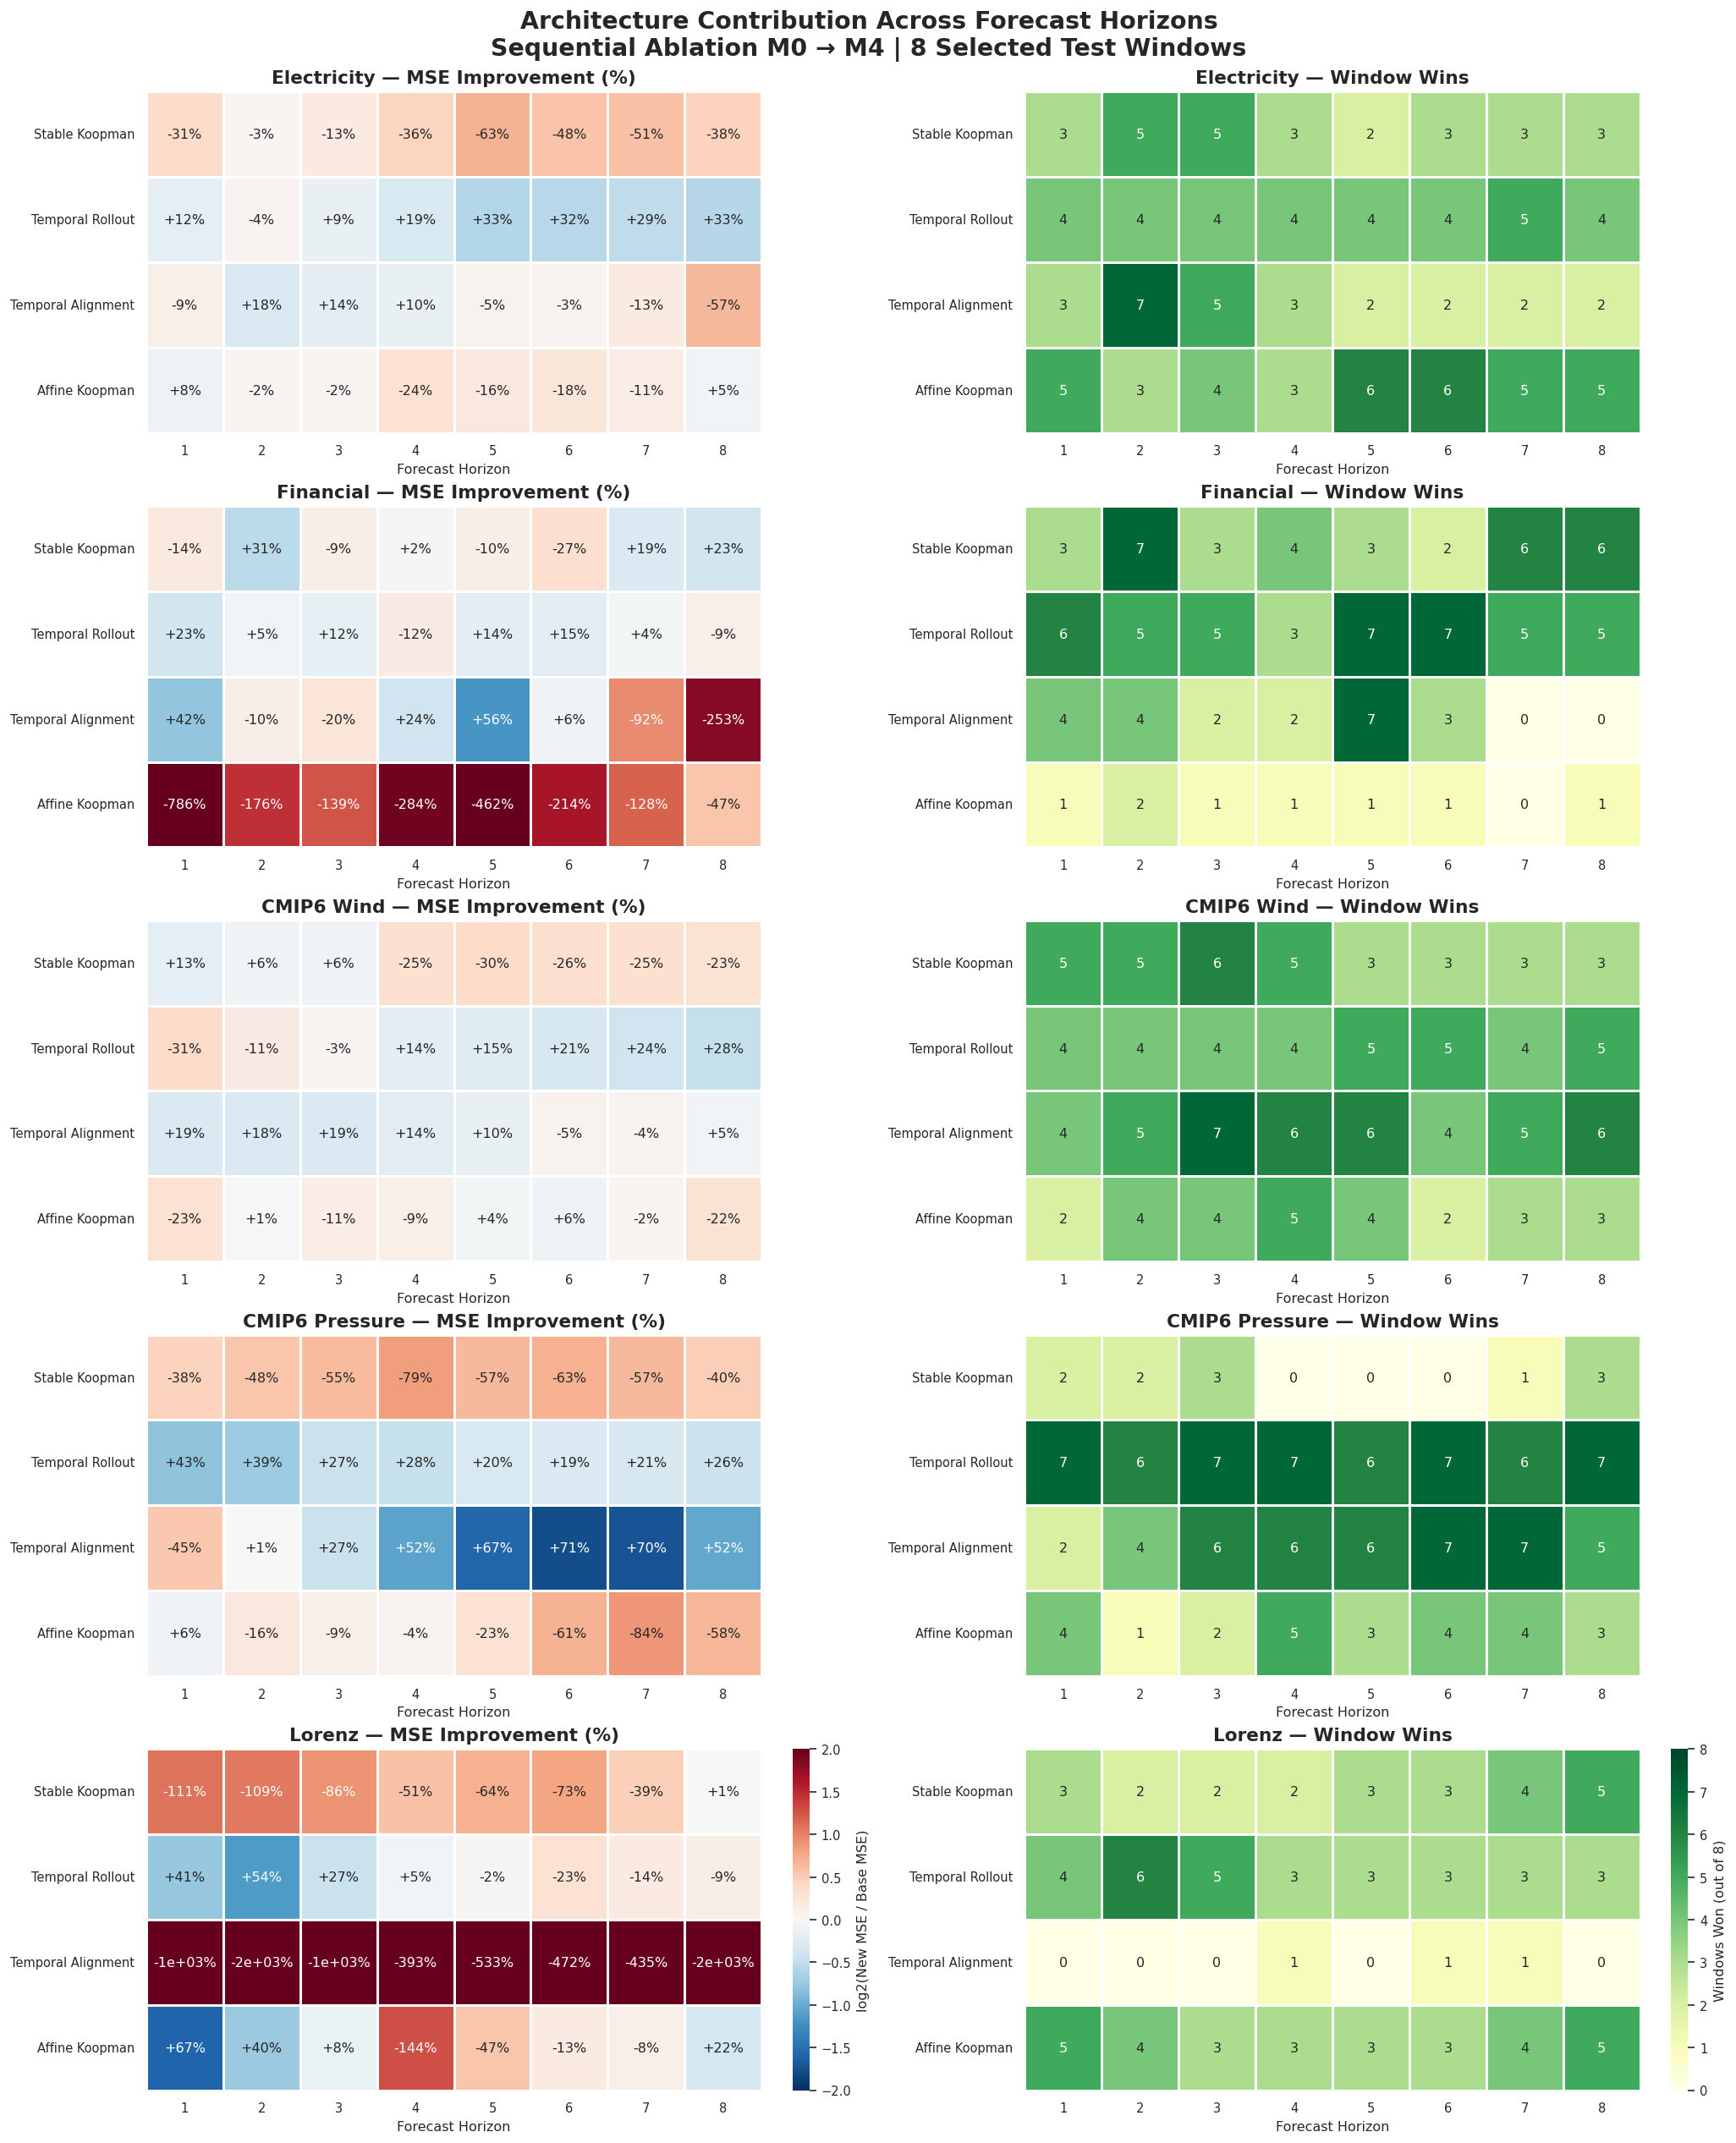

OVERALL ARCHITECTURE CONTRIBUTION


,dataset,component,improvement_pct,win_rate_pct,improvement_h1_pct,improvement_h8_pct
0,CMIP6 Pressure,Affine Koopman,-44.07%,40.6%,+5.55%,-57.83%
1,CMIP6 Pressure,Stable Koopman,-53.22%,17.2%,-37.50%,-40.02%
2,CMIP6 Pressure,Temporal Alignment,+56.99%,67.2%,-44.53%,+51.51%
3,CMIP6 Pressure,Temporal Rollout,+23.83%,82.8%,+42.91%,+25.53%
4,CMIP6 Wind,Affine Koopman,-3.79%,42.2%,-23.19%,-22.11%
5,CMIP6 Wind,Stable Koopman,-17.92%,51.6%,+12.53%,-22.65%
6,CMIP6 Wind,Temporal Alignment,+7.49%,67.2%,+19.36%,+4.60%
7,CMIP6 Wind,Temporal Rollout,+13.84%,54.7%,-30.96%,+28.40%
8,Electricity,Affine Koopman,-7.61%,57.8%,+8.16%,+5.16%
9,Electricity,Stable Koopman,-36.60%,42.2%,-30.88%,-37.86%



IMPROVEMENT AT HORIZON 8


component,Stable Koopman,Temporal Rollout,Temporal Alignment,Affine Koopman
dataset,,,,
Electricity,-37.9%,+32.8%,-56.6%,+5.2%
Financial,+22.9%,-8.7%,-253.4%,-47.3%
CMIP6 Wind,-22.7%,+28.4%,+4.6%,-22.1%
CMIP6 Pressure,-40.0%,+25.5%,+51.5%,-57.8%
Lorenz,+0.9%,-9.2%,-1809.4%,+21.7%



[PASS] Architecture contribution analysis completed


In [10]:
ARCHITECTURE_PAIRS = [
    ("M0", "M1", "Stable Koopman"),
    ("M1", "M2", "Temporal Rollout"),
    ("M2", "M3", "Temporal Alignment"),
    ("M3", "M4", "Affine Koopman")
]

pair_horizon_records = []

for dataset in DATASETS:
    bundle = forecast_data[dataset]

    actual = bundle["y"].astype(np.float64)
    predictions = bundle["predictions"]

    n_windows, n_channels, horizon = actual.shape

    assert horizon == HORIZON

    for base_model, new_model, component in ARCHITECTURE_PAIRS:
        base_pred = predictions[base_model].astype(np.float64)
        new_pred = predictions[new_model].astype(np.float64)

        assert base_pred.shape == actual.shape
        assert new_pred.shape == actual.shape

        base_error = (base_pred - actual) ** 2
        new_error = (new_pred - actual) ** 2

        for h in range(HORIZON):
            for w in range(n_windows):
                base_mse = float(
                    np.mean(base_error[w, :, h])
                )

                new_mse = float(
                    np.mean(new_error[w, :, h])
                )

                pair_horizon_records.append({
                    "dataset": dataset,
                    "component": component,
                    "base_model": base_model,
                    "new_model": new_model,
                    "horizon_step": h + 1,
                    "sample_position": w,
                    "base_mse": base_mse,
                    "new_mse": new_mse,
                    "improvement_absolute": base_mse - new_mse,
                    "new_model_wins": new_mse < base_mse
                })

pair_horizon_df = pd.DataFrame(pair_horizon_records)

assert len(pair_horizon_df) == (
    len(DATASETS) * len(ARCHITECTURE_PAIRS) * HORIZON * 8
)

component_summary = (
    pair_horizon_df.groupby(
        [
            "dataset",
            "component",
            "base_model",
            "new_model",
            "horizon_step"
        ],
        as_index=False
    )
    .agg(
        mean_base_mse=("base_mse", "mean"),
        mean_new_mse=("new_mse", "mean"),
        windows_won=("new_model_wins", "sum"),
        n_windows=("new_model_wins", "size")
    )
)

component_summary["improvement_pct"] = (
    100 * (
        1 - component_summary["mean_new_mse"]
        / component_summary["mean_base_mse"].clip(lower=1e-15)
    )
)

component_summary["log2_mse_ratio"] = np.log2(
    component_summary["mean_new_mse"].clip(lower=1e-15)
    / component_summary["mean_base_mse"].clip(lower=1e-15)
)

component_order = [
    pair[2] for pair in ARCHITECTURE_PAIRS
]

fig, axes = plt.subplots(
    len(DATASETS),
    2,
    figsize=(17, 21),
    constrained_layout=True
)

for i, dataset in enumerate(DATASETS):
    subset = component_summary[
        component_summary["dataset"] == dataset
    ]

    improvement_matrix = subset.pivot(
        index="component",
        columns="horizon_step",
        values="log2_mse_ratio"
    ).reindex(
        index=component_order,
        columns=range(1, HORIZON + 1)
    )

    raw_improvement = subset.pivot(
        index="component",
        columns="horizon_step",
        values="improvement_pct"
    ).reindex(
        index=component_order,
        columns=range(1, HORIZON + 1)
    )

    win_matrix = subset.pivot(
        index="component",
        columns="horizon_step",
        values="windows_won"
    ).reindex(
        index=component_order,
        columns=range(1, HORIZON + 1)
    )

    improvement_labels = raw_improvement.apply(
        lambda col: col.map(
            lambda value: (
                f"{value:+.0f}%"
                if abs(value) < 1000
                else f"{value:+.0e}%"
            )
        )
    )

    sns.heatmap(
        improvement_matrix,
        annot=improvement_labels,
        fmt="",
        cmap="RdBu_r",
        center=0,
        vmin=-2,
        vmax=2,
        linewidths=0.8,
        linecolor="white",
        cbar=(i == len(DATASETS) - 1),
        cbar_kws={
            "label": "log2(New MSE / Base MSE)"
        } if i == len(DATASETS) - 1 else None,
        ax=axes[i, 0]
    )

    sns.heatmap(
        win_matrix,
        annot=True,
        fmt=".0f",
        cmap="YlGn",
        vmin=0,
        vmax=8,
        linewidths=0.8,
        linecolor="white",
        cbar=(i == len(DATASETS) - 1),
        cbar_kws={
            "label": "Windows Won (out of 8)"
        } if i == len(DATASETS) - 1 else None,
        ax=axes[i, 1]
    )

    axes[i, 0].set_title(
        f"{dataset} — MSE Improvement (%)",
        fontweight="bold",
        fontsize=13
    )

    axes[i, 1].set_title(
        f"{dataset} — Window Wins",
        fontweight="bold",
        fontsize=13
    )

    for ax in axes[i]:
        ax.set_xlabel("Forecast Horizon")
        ax.set_ylabel("")

fig.suptitle(
    "Architecture Contribution Across Forecast Horizons\n"
    "Sequential Ablation M0 → M4 | 8 Selected Test Windows",
    fontsize=17,
    fontweight="bold"
)

fig.savefig(
    FIGURES_DIR / "fig06_architecture_horizon_contribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "fig06_architecture_horizon_contribution.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

component_overall = (
    pair_horizon_df.groupby(
        ["dataset", "component", "base_model", "new_model"],
        as_index=False
    )
    .agg(
        mean_base_mse=("base_mse", "mean"),
        mean_new_mse=("new_mse", "mean"),
        winning_window_leads=("new_model_wins", "sum"),
        total_window_leads=("new_model_wins", "size")
    )
)

component_overall["improvement_pct"] = (
    100 * (
        1 - component_overall["mean_new_mse"]
        / component_overall["mean_base_mse"].clip(lower=1e-15)
    )
)

component_overall["win_rate_pct"] = (
    100 * component_overall["winning_window_leads"]
    / component_overall["total_window_leads"]
)

h1_h8 = component_summary[
    component_summary["horizon_step"].isin([1, HORIZON])
].pivot(
    index=["dataset", "component"],
    columns="horizon_step",
    values="improvement_pct"
).rename(columns={
    1: "improvement_h1_pct",
    HORIZON: "improvement_h8_pct"
}).reset_index()

component_overall = component_overall.merge(
    h1_h8,
    on=["dataset", "component"],
    validate="one_to_one"
)

print("OVERALL ARCHITECTURE CONTRIBUTION")

display(
    component_overall[
        [
            "dataset",
            "component",
            "improvement_pct",
            "win_rate_pct",
            "improvement_h1_pct",
            "improvement_h8_pct"
        ]
    ].style.format({
        "improvement_pct": "{:+.2f}%",
        "win_rate_pct": "{:.1f}%",
        "improvement_h1_pct": "{:+.2f}%",
        "improvement_h8_pct": "{:+.2f}%"
    })
)

print("\nIMPROVEMENT AT HORIZON 8")

display(
    component_overall.pivot(
        index="dataset",
        columns="component",
        values="improvement_h8_pct"
    ).reindex(
        index=DATASETS,
        columns=component_order
    ).style.format("{:+.1f}%")
)

pair_horizon_df.to_csv(
    FIGURES_DIR / "architecture_window_horizon_errors.csv",
    index=False
)

component_summary.to_csv(
    FIGURES_DIR / "architecture_horizon_contribution.csv",
    index=False
)

component_overall.to_csv(
    FIGURES_DIR / "architecture_contribution_summary.csv",
    index=False
)

print("\n[PASS] Architecture contribution analysis completed")


In [11]:
import hashlib
import shutil
from datetime import datetime, timezone

VIS_ROOT = (
    PROJECT_ROOT
    / "research_xai"
    / "notebooks"
    / "visualization"
)

EXPORT_DIR = VIS_ROOT / "data" / "forecasting"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

summary_records = []

for dataset, dataset_key in DATASET_MAP.items():
    bundle = forecast_data[dataset]

    x = np.asarray(bundle["x"])
    y = np.asarray(bundle["y"])
    indices = np.asarray(bundle["sample_indices"])

    n_windows, n_channels, horizon = y.shape

    assert n_windows == 8
    assert horizon == HORIZON
    assert x.shape == (n_windows, LOOKBACK, n_channels)
    assert indices.shape == (n_windows,)

    export_arrays = {
        "x": x,
        "y": y,
        "sample_indices": indices
    }

    for model in MODEL_ORDER:
        pred = np.asarray(
            bundle["predictions"][model]
        )

        assert pred.shape == y.shape
        assert np.isfinite(pred).all()

        mse = float(np.mean(
            (pred.astype(np.float64) - y) ** 2
        ))

        mae = float(np.mean(
            np.abs(pred.astype(np.float64) - y)
        ))

        source_mse = verification_df.loc[
            (verification_df["dataset"] == dataset)
            & (verification_df["model"] == model),
            "selected_windows_mse"
        ]

        assert len(source_mse) == 1

        np.testing.assert_allclose(
            mse,
            float(source_mse.iloc[0]),
            rtol=1e-5,
            atol=1e-9
        )

        window_mean = window_errors_df.loc[
            (window_errors_df["dataset"] == dataset)
            & (window_errors_df["model"] == model),
            "window_mse"
        ].mean()

        channel_mean = channel_df.loc[
            (channel_df["dataset"] == dataset)
            & (channel_df["model"] == model),
            "mse"
        ].mean()

        horizon_mean = horizon_df.loc[
            (horizon_df["dataset"] == dataset)
            & (horizon_df["model"] == model),
            "mse"
        ].mean()

        for checked_mse in [
            window_mean,
            channel_mean,
            horizon_mean
        ]:
            np.testing.assert_allclose(
                mse,
                checked_mse,
                rtol=1e-6,
                atol=1e-10
            )

        summary_records.append({
            "dataset": dataset,
            "model": model,
            "n_windows": n_windows,
            "n_channels": n_channels,
            "horizon": horizon,
            "mse_8windows": mse,
            "mae_8windows": mae,
            "consistent": True
        })

        export_arrays[f"pred_{model}"] = pred

    np.savez_compressed(
        EXPORT_DIR / f"forecasts_{dataset_key}.npz",
        **export_arrays
    )

forecast_final_df = pd.DataFrame(summary_records)

assert len(forecast_final_df) == 35
assert forecast_final_df["consistent"].all()

assert len(validation_df) == 35
assert len(window_errors_df) == 280
assert len(channel_df) == sum(
    forecast_data[d]["y"].shape[1]
    for d in DATASETS
) * len(MODEL_ORDER)
assert len(horizon_df) == 280
assert len(pair_horizon_df) == 1280
assert len(case_df) == 10

expected_figures = []

for dataset_key in DATASET_MAP.values():
    expected_figures.extend([
        f"fig01_actual_vs_pred_{dataset_key}",
        f"fig03_multichannel_{dataset_key}",
        f"fig05_case_study_{dataset_key}"
    ])

expected_figures.extend([
    "fig02_window_consistency",
    "fig04_horizon_error",
    "fig06_architecture_horizon_contribution"
])

for name in expected_figures:
    for extension in [".png", ".pdf"]:
        path = FIGURES_DIR / f"{name}{extension}"

        if not path.is_file():
            raise FileNotFoundError(path)

required_csvs = [
    "forecast_source_verification.csv",
    "forecast_consistency_validation.csv",
    "selected_forecast_cases.csv",
    "actual_vs_pred_window_metrics.csv",
    "window_level_forecast_errors.csv",
    "window_consistency_summary.csv",
    "window_winners.csv",
    "channel_forecast_metrics_8windows.csv",
    "channel_best_models.csv",
    "channel_winner_counts.csv",
    "horizon_level_forecast_errors.csv",
    "horizon_error_growth_summary.csv",
    "best_models_at_horizon8.csv",
    "forecast_case_selection.csv",
    "forecast_case_model_metrics.csv",
    "architecture_window_horizon_errors.csv",
    "architecture_horizon_contribution.csv",
    "architecture_contribution_summary.csv"
]

for filename in required_csvs:
    source = FIGURES_DIR / filename

    if not source.is_file():
        raise FileNotFoundError(source)

export_csvs = [
    "selected_forecast_cases.csv",
    "window_consistency_summary.csv",
    "channel_forecast_metrics_8windows.csv",
    "horizon_error_growth_summary.csv",
    "forecast_case_selection.csv",
    "architecture_contribution_summary.csv"
]

forecast_final_df.to_csv(
    EXPORT_DIR / "forecast_metrics_8windows.csv",
    index=False
)

for filename in export_csvs:
    shutil.copy2(
        FIGURES_DIR / filename,
        EXPORT_DIR / filename
    )

manifest = {
    "project": "DeepKoopFormer XAI",
    "notebook": "02_forecasting.ipynb",
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "lookback": LOOKBACK,
    "horizon": HORIZON,
    "seed": SEED,
    "datasets": DATASETS,
    "models": MODEL_ORDER,
    "n_selected_windows_per_dataset": 8,
    "total_forecast_sources": 35,
    "validation": {
        "source_verified": True,
        "window_mse_consistent": True,
        "channel_mse_consistent": True,
        "horizon_mse_consistent": True
    },
    "limitation": (
        "Forecasting visualizations use 8 preselected "
        "test windows per dataset, not the complete test set."
    ),
    "files": {}
}

for path in sorted(EXPORT_DIR.iterdir()):
    if not path.is_file():
        continue

    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    manifest["files"][path.name] = {
        "bytes": path.stat().st_size,
        "sha256": digest
    }

manifest_path = EXPORT_DIR / "forecast_manifest.json"

manifest_path.write_text(
    json.dumps(
        manifest,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("FORECASTING VALIDATION")
print("Sources verified: 35/35")
print("Window-level results: 280/280")
print("Horizon-level results: 280/280")
print("Architecture comparisons: 1280/1280")
print("Figures:", len(expected_figures), "/18")
print("CSV files:", len(required_csvs), "/18")
print("Exported NPZ files: 5/5")

print("\nFINAL MSE ON 8 SELECTED WINDOWS")

display(
    forecast_final_df.pivot(
        index="dataset",
        columns="model",
        values="mse_8windows"
    ).reindex(
        index=DATASETS,
        columns=MODEL_ORDER
    ).style.format("{:.8f}")
)

print("\nBEST MODEL PER DATASET")

best_models = (
    forecast_final_df.loc[
        forecast_final_df.groupby("dataset")[
            "mse_8windows"
        ].idxmin()
    ]
    [["dataset", "model", "mse_8windows"]]
    .set_index("dataset")
    .reindex(DATASETS)
)

display(best_models)

print("\nExport directory:", EXPORT_DIR)
print("Manifest:", manifest_path)
print("\n[DONE] Notebook 02 forecasting completed")


FORECASTING VALIDATION
Sources verified: 35/35
Window-level results: 280/280
Horizon-level results: 280/280
Architecture comparisons: 1280/1280
Figures: 18 /18
CSV files: 18 /18
Exported NPZ files: 5/5

FINAL MSE ON 8 SELECTED WINDOWS


model,M0,M1,M2,M3,M4,LSTM,DLinear
dataset,,,,,,,
Electricity,0.01519279,0.02075262,0.01585798,0.01682807,0.01810855,0.01770382,0.01112230
Financial,0.00291118,0.00277613,0.00261294,0.00390764,0.00960724,0.00065902,0.00061088
CMIP6 Wind,0.03526458,0.04158415,0.03582927,0.03314422,0.03440070,0.02781462,0.02187704
CMIP6 Pressure,0.00675349,0.01034766,0.00788214,0.00339011,0.00488414,0.00237062,0.00227076
Lorenz,0.00006189,0.00009677,0.00008886,0.00084805,0.00081892,0.00005772,0.00094618



BEST MODEL PER DATASET


,model,mse_8windows
dataset,,
Electricity,DLinear,0.011122
Financial,DLinear,0.000611
CMIP6 Wind,DLinear,0.021877
CMIP6 Pressure,DLinear,0.002271
Lorenz,LSTM,0.000058



Export directory: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\data\forecasting
Manifest: C:\Users\Win 11 New\Desktop\pa gk\research_xai\notebooks\visualization\data\forecasting\forecast_manifest.json

[DONE] Notebook 02 forecasting completed
